# The Positive India
## Is the article heartwarming?

    There are a myriad of websites on the internet that show news articles from so many categories: politics, sports, entertainment on and on. With all of these homogenous news the silver lining in our society is - in a way - overlooked. The Positive India is one of those very few websites that concentrates on spreading heartwarming news across the country to raise awareness on how India has so many stories to take inspiration from.
    
    To support The Positive India with AI we take it upon us to make a computer understand how to distinguish between heartwarming and other articles.


### Import Libraries

In [ ]:
#General imports and preprocessing
import os
import numpy as np
import pandas as pd
pd.set_option('display.max_columns',200)
import re
from tqdm.notebook import tqdm
tqdm.pandas()
import warnings
warnings.filterwarnings('ignore')

#Feature Extraction
from sklearn.feature_extraction.text import CountVectorizer 
from sklearn.feature_extraction.text import TfidfVectorizer

#Feature engineering
from nltk import tokenize
englishStopWords = stopwords.words('english')
from textblob import TextBlob
from nltk.corpus import stopwords
from nltk import pos_tag
import gensim.models.keyedvectors as word2vec
wv = word2vec.KeyedVectors.load_word2vec_format("/Users/gurumanikanta/Documents/DS-Analytics/GoogleNews-vectors-negative300.bin.gz",binary=True)
from nltk.corpus import wordnet as wn
from nltk.corpus import sentiwordnet as swn
from nltk.stem import WordNetLemmatizer
from scipy.spatial.distance import cosine

#Visualization
from wordcloud import WordCloud
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

#Transformations
from sklearn.preprocessing import minmax_scale

#Modeling
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn import svm
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import pickle, joblib


## Preprocessing and Basic Feature Engineering

In [13]:
def get_basic_features(df):
    '''Creates basic features for the given text'''
    text = str(df['content'])
    text_split = text.split()
    upper_count = 0
    upper_words = list()
    word_count = 0
    numeric_count = 0
    each_word_len = list()
    text_length = len(text)
    #sometimes punctuations might include space
    punct_count = len(re.sub('\w+','',text).split())
    unique_word_count = len(pd.value_counts(text_split).index)
    for word in text_split:
        word_count += 1
        each_word_len.append(len(word))
        if word.isupper() and len(word)>1:
            upper_count += 1
            upper_words.append(word)
        elif word.isnumeric():
            numeric_count += 1
    return upper_count, upper_words, word_count, np.mean(each_word_len), text_length, punct_count, numeric_count, unique_word_count



def stop_words_percent(text):
    '''find the percentage of stop words in each article'''
    try:
        words_in_text = text.split()
        return len([word for word in words_in_text if word in englishStopWords])/len(words_in_text)
    except:
        return 0


#list of all common columns for concatination
column_list = ['content','actual_heading','clean_content','upper_words','upper_count','word_count',
               'mean(each_word_len)','unique_word_count','punct_count','numeric_count','text_length',
               'stop_words_percent','is_positive']


## The Better India articles

In [18]:
#First time procssing raw articles
def clean_articles(text):
    '''cleans one article at a time - removes punctuation, leading and trailing unwanted text if any, standardize case
    and returns the tokenized text
    all the characters encoded are quotation marks, hifen or someother form of punctuation, either way we will be 
    removing them so its better to directly replace all the non-word charcters before decoding them to keep the number 
    of steps to a minimum'''

    temp = re.sub("\W+",' ',text)
    temp = re.sub(" s |by.*?[am|pm] |Get the best positive stories straight into your inbox",' ',temp).lower().strip()
    try:
        temp = re.sub(r"\n",'',text)
        temp = re.sub(r"\[.*\]",'',temp)
    except:
        temp = text
        pass

    return temp

tbi_data['clean_content'] = tbi_data['content'].apply(clean_articles)
tbi_data[['upper_count', 'upper_words', 'word_count', 'mean(each_word_len)', 'text_length', 'punct_count', 'numeric_count', 'unique_word_count']] = tbi_data.apply(get_basic_features, axis=1, result_type='expand')
tbi_data['stop_words_percent'] = tbi_data['content'].apply(lambda val: stop_words_percent(val))
tbi_data['is_positive'] = 1

In [23]:
#preprocessed and stored articles
tbi_data = pd.read_csv("/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/tbi_data.csv")
tbi_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6620 entries, 0 to 6619
Data columns (total 13 columns):
content                6620 non-null object
actual_heading         6620 non-null object
clean_content          6620 non-null object
upper_words            6620 non-null object
upper_count            6620 non-null int64
word_count             6620 non-null int64
mean(each_word_len)    6620 non-null float64
unique_word_count      6620 non-null int64
punct_count            6620 non-null int64
numeric_count          6620 non-null int64
text_length            6620 non-null int64
stop_words_percent     6620 non-null float64
is_positive            6620 non-null int64
dtypes: float64(2), int64(7), object(4)
memory usage: 672.5+ KB


### Indian Express Articles

In [21]:
#first time processing

ie_path = '/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/IndianExpress/'
ie_files_list = os.listdir(ie_path)
ie_data = pd.DataFrame()
for file in ie_files_list[:15]:
    ie_data = pd.concat([ie_data,pd.read_csv(ie_path+file,encoding='unicode-escape')])
    
ie_data.drop(labels=['Unnamed: 0'],inplace=True,axis=1)
ie_data.reset_index(drop=True,inplace=True)
ie_data.head()

ie_data['Heading'] = ie_data['Heading'].apply(lambda heading: re.sub(' - Indian Express $| - Indian Express$|\W+',' ',heading).strip())
ie_data['Content'] = ie_data['Content'].apply(lambda content: re.sub(r'\r\n|\r<p>','',content).strip())
ie_data['Clean_content'] = ie_data['Content'].apply(lambda content: re.sub('[^ \w+]','',content.replace('.','. ').lower()))

ie_data.rename(columns={'Heading':'actual_heading','Content':'content','Clean_content':'clean_content'},inplace=True)

ie_data[['upper_count', 'upper_words', 'word_count', 'mean(each_word_len)', 'text_length', 'punct_count', 'numeric_count', 'unique_word_count']] = ie_data.apply(get_basic_features,axis=1,result_type='expand')
ie_data['stop_words_percent'] = ie_data['content'].apply(lambda val: stop_words_percent(val))
ie_data['is_positive'] = 0

ie_data = ie_data[column_list]


In [22]:
#preprocessed and stored articles 15k
ie_path = '/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/IndianExpress/'
ie_data = pd.read_csv(ie_path+'ie_data_15k.csv')
ie_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15015 entries, 0 to 15014
Data columns (total 13 columns):
content                15015 non-null object
actual_heading         15015 non-null object
clean_content          15015 non-null object
upper_words            15015 non-null object
upper_count            15015 non-null int64
word_count             15015 non-null int64
mean(each_word_len)    15015 non-null float64
unique_word_count      15015 non-null int64
punct_count            15015 non-null int64
numeric_count          15015 non-null int64
text_length            15015 non-null int64
stop_words_percent     15015 non-null float64
is_positive            15015 non-null int64
dtypes: float64(2), int64(7), object(4)
memory usage: 1.5+ MB


## TOI articles

In [14]:
#toi_data = pd.read_csv('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TOI/toi_10k.csv')
#toi_data.dropna(inplace=True)

def clean_toi(text):    
    '''cleans the text by removing new line, trailing and leading single quote, encoded characters. We do not have any html tags to clean'''
    try:
        temp = re.sub(r"\\n"," ",text)
        temp = re.sub(r"\\x[a-z][0-9]*|\\x[0-9]*","'",temp)
        temp = re.sub(r"'''","'",temp)
        temp = re.sub(r"^b'|^b\"","",temp)
        temp = re.sub(r"'$","",temp).strip().lower()

        return temp
    except:
        return None

toi_data.rename(columns={'heading':'actual_heading'},inplace=True)
toi_data['clean_content'] = toi_data['content'].apply(clean_toi)
toi_data[['upper_count', 'upper_words', 'word_count', 'mean(each_word_len)', 'text_length', 'punct_count', 'numeric_count', 'unique_word_count']] = toi_data.apply(get_basic_features,axis=1,result_type='expand')
toi_data['stop_words_percent'] = toi_data['content'].apply(lambda val: stop_words_percent(val))
toi_data['is_positive'] = 0

In [21]:
#read the preprocessed articles around 13k from csv
toi_data = pd.read_csv('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/TOI/toi_data_13k.csv')
toi_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12718 entries, 0 to 12717
Data columns (total 13 columns):
actual_heading         12718 non-null object
content                12718 non-null object
clean_content          12718 non-null object
upper_count            12718 non-null int64
upper_words            12718 non-null object
word_count             12718 non-null int64
mean(each_word_len)    12718 non-null float64
text_length            12718 non-null int64
punct_count            12718 non-null int64
numeric_count          12718 non-null int64
unique_word_count      12718 non-null int64
stop_words_percent     12718 non-null float64
is_positive            12718 non-null int64
dtypes: float64(2), int64(7), object(4)
memory usage: 1.3+ MB


## All data

In [145]:
#concat all the dataframes
#all_data = pd.concat([tbi_data[column_list],ie_data[column_list],toi_data[column_list]],ignore_index=True)

contractions = { 
"ain't": "am not / are not / is not / has not / have not",
"aren't": "are not / am not",
"can't": "cannot",
"can't've": "cannot have",
"'cause": "because",
"could've": "could have",
"couldn't": "could not",
"couldn't've": "could not have",
"didn't": "did not",
"doesn't": "does not",
"don't": "do not",
"hadn't": "had not",
"hadn't've": "had not have",
"hasn't": "has not",
"haven't": "have not",
"he'd": "he had / he would",
"he'd've": "he would have",
"he'll": "he shall / he will",
"he'll've": "he shall have / he will have",
"he's": "he has / he is",
"how'd": "how did",
"how'd'y": "how do you",
"how'll": "how will",
"how's": "how has / how is / how does",
"I'd": "I had / I would",
"I'd've": "I would have",
"I'll": "I shall / I will",
"I'll've": "I shall have / I will have",
"I'm": "I am",
"I've": "I have",
"isn't": "is not",
"it'd": "it had / it would",
"it'd've": "it would have",
"it'll": "it shall / it will",
"it'll've": "it shall have / it will have",
"it's": "it has / it is",
"let's": "let us",
"ma'am": "madam",
"mayn't": "may not",
"might've": "might have",
"mightn't": "might not",
"mightn't've": "might not have",
"must've": "must have",
"mustn't": "must not",
"mustn't've": "must not have",
"needn't": "need not",
"needn't've": "need not have",
"o'clock": "of the clock",
"oughtn't": "ought not",
"oughtn't've": "ought not have",
"shan't": "shall not",
"sha'n't": "shall not",
"shan't've": "shall not have",
"she'd": "she had / she would",
"she'd've": "she would have",
"she'll": "she shall / she will",
"she'll've": "she shall have / she will have",
"she's": "she has / she is",
"should've": "should have",
"shouldn't": "should not",
"shouldn't've": "should not have",
"so've": "so have",
"so's": "so as / so is",
"that'd": "that would / that had",
"that'd've": "that would have",
"that's": "that has / that is",
"there'd": "there had / there would",
"there'd've": "there would have",
"there's": "there has / there is",
"they'd": "they had / they would",
"they'd've": "they would have",
"they'll": "they shall / they will",
"they'll've": "they shall have / they will have",
"they're": "they are",
"they've": "they have",
"to've": "to have",
"wasn't": "was not",
"we'd": "we had / we would",
"we'd've": "we would have",
"we'll": "we will",
"we'll've": "we will have",
"we're": "we are",
"we've": "we have",
"weren't": "were not",
"what'll": "what shall / what will",
"what'll've": "what shall have / what will have",
"what're": "what are",
"what's": "what has / what is",
"what've": "what have",
"when's": "when has / when is",
"when've": "when have",
"where'd": "where did",
"where's": "where has / where is",
"where've": "where have",
"who'll": "who shall / who will",
"who'll've": "who shall have / who will have",
"who's": "who has / who is",
"who've": "who have",
"why's": "why has / why is",
"why've": "why have",
"will've": "will have",
"won't": "will not",
"won't've": "will not have",
"would've": "would have",
"wouldn't": "would not",
"wouldn't've": "would not have",
"y'all": "you all",
"y'all'd": "you all would",
"y'all'd've": "you all would have",
"y'all're": "you all are",
"y'all've": "you all have",
"you'd": "you had / you would",
"you'd've": "you would have",
"you'll": "you shall / you will",
"you'll've": "you shall have / you will have",
"you're": "you are",
"you've": "you have"
}

In [ ]:
def rem_contractions(text):
    text = str(text)
    rep = dict((re.escape(k), v) for k, v in contractions.items()) 
    pattern = re.compile("|".join(rep.keys()))
    text = pattern.sub(lambda m: rep[re.escape(m.group(0))], text)
    return text


def lemmatize_with_postag(sentence):
    sentence = str(sentence)
    sent = TextBlob(sentence)
    tag_dict = {"J": 'a', 
                "N": 'n', 
                "V": 'v', 
                "R": 'r'}
    words_and_tags = [(w, tag_dict.get(pos[0], 'n')) for w, pos in sent.tags]    
    lemmatized_list = [wd.lemmatize(tag) for wd, tag in words_and_tags if wd not in englishStopWords]
    return " ".join(lemmatized_list)



def pos_sentence(text):
    '''converts a text with words to text with pos tags for the respective words'''
    text = str(text)
    words_and_tags = pos_tag(text.split())
    pos_sent = list()
    for word, tag in words_and_tags:
        pos_sent.append(tag)
        
    return ' '.join(pos_sent)


In [ ]:
#from operator import itemgetter
def most_used_adjectives(row,top=5):
    text = str(row['lemmatized_content'])
    adj_list = list()
    #currently -3 index is lemmatized text
    sent_split = text.split()
    for word,tag in pos_tag(sent_split):
        if tag.lower() in ['jj','jjr','jjs']:
            adj_list.append(word)

    
    return list(pd.value_counts(adj_list).index[:top]),len(adj_list)



wv = word2vec.KeyedVectors.load_word2vec_format("/Users/gurumanikanta/Documents/DS-Analytics/GoogleNews-vectors-negative300.bin.gz",binary=True)



In [ ]:
###most used adjectives similarity with words "good" and "bad" to determine the goodness of articles
def pos_neg_score(row):
    '''returns the average positive/negative scores based on top adjectives'''
    pos_score = 0
    neg_score = 0
    adjectives = row['most_used_adjectives']
    num_adj = len(adjectives)
    for adj in adjectives:
        try:
            pos_score = pos_score + wv.similarity(adj,'good')
        except:
            pass
        try:
            neg_score = neg_score + wv.similarity(adj,'neg')
        except:
            pass
    
    if num_adj == 0:
        avg_pos, avg_neg = 0, 0
    else:
        avg_pos, avg_neg = pos_score/num_adj, neg_score/num_adj
        
    return avg_pos, avg_neg



In [ ]:
def doc_similarity_to_pos(sim_demo):
    '''calculates the similarity of all articles to the positive articles'''
    cos_sim = dict()
    vocab = wv.vocab
    for i in range(6628):
        pos_article = sim_demo['lemmatized_content'][i]
        if not pd.isnull(pos_article):
            pos_vec = np.mean([wv[word] for word in pos_article.split() if (word in vocab)],axis=0)
            cos_sim['article_'+str(i)] = list()
            for d in range(len(sim_demo)):
                demo_article = sim_demo['lemmatized_content'][d]
                if not pd.isnull(demo_article):
                    demo_vec = np.mean([wv[word] for word in demo_article.split() if (word in vocab)],axis=0)
                    cos_sim['article_'+str(i)].append(cosine(pos_vec,demo_vec))
                else:
                    cos_sim['article_'+str(i)].append(None)
        else:
            continue

    for key in cos_sim.keys():
        cos_sim[key] = np.mean(cos_sim['key'])

    sim_df = pd.DataFrame(data=cos_sim)
    return sim_df.apply(np.mean,axis=1)


####sentiments
def penn_to_wn(tag):
    #Convert between the PennTreebank tags to simple Wordnet tags
    if tag.startswith('J'):
        return wn.ADJ
    elif tag.startswith('N'):
        return wn.NOUN
    elif tag.startswith('R'):
        return wn.ADV
    elif tag.startswith('V'):
        return wn.VERB
    return None

In [ ]:
lemmatizer = WordNetLemmatizer()
def get_document_sentiment(text):
    text = str(text)
    score = 0.0
    tokens_count = 0
 
    tagged_text = pos_tag(tokenize.word_tokenize(str(text)))

    for word, tag in tagged_text:
        wn_tag = penn_to_wn(tag)
        if wn_tag not in (wn.NOUN, wn.ADJ, wn.ADV):
            continue

        lemma = lemmatizer.lemmatize(word, pos=wn_tag)
        if not lemma:
            continue

        synsets = wn.synsets(lemma, pos=wn_tag)
        if not synsets:
            continue

        # The most commonly used form of the word
        synset = synsets[0]
        swn_synset = swn.senti_synset(synset.name())

        score += swn_synset.pos_score() - swn_synset.neg_score()
        tokens_count += 1

    if not tokens_count:
        return 0
 
    return score/tokens_count


In [ ]:
def mean_adjective_length(row):
    '''iterates one row at a time, identifies all adjectives and returns mean length of all adjectives'''
    text = str(row['lemmatized_content'])
    adj_list = list()
    adj_len_list = list()
    
    try:                
        sent_split = text.split()
        for word,tag in pos_tag(sent_split):
            if tag.lower() in ['jj','jjr','jjs']:
                adj_list.append(word)
                adj_len_list.append(len(word))
                

        return np.mean(np.array(adj_len_list)),' '.join(adj_list)
    except:
        return 0


def norm_numerical_features(all_data_temp):
    '''Creates a normalized feature for all the numerical features available'''
    all_data_temp['norm_adj_count'] = all_data_temp['adj_count']/all_data_temp['word_count']
    all_data_temp['norm_upper_count'] = all_data_temp['upper_count']/all_data_temp['word_count']
    all_data_temp['norm_numeric_count'] = all_data_temp['numeric_count']/all_data_temp['word_count']
    all_data_temp['norm_unique_word_count'] = all_data_temp['unique_word_count']/all_data_temp['word_count']
    all_data_temp['norm_punct_count'] = all_data_temp['punct_count']/all_data_temp['text_length']

    return all_data_temp

In [30]:
all_data = norm_numerical_features(all_data)
all_data['content_sentiment'] = all_data['clean_content'].apply(get_document_sentiment)
all_data['clean_content'] = all_data['clean_content'].apply(rem_contractions)
all_data['lemmatized_content'][6620:21635] = all_data['clean_content'].apply(lemmatize_with_postag)
all_data['pos_content'] = all_data['lemmatized_content'].apply(pos_sentence)
all_data[['most_used_adjectives','adj_count']] = all_data.apply(most_used_adjectives,axis=1,result_type='expand')
all_data[['positive_score','negative_score']] = all_data.apply(pos_neg_score,axis=1,result_type='expand')
#all_data['similarity_to_pos'] = doc_similarity_to_pos(all_data)
all_data[['mean_adj_length','all_adjs']] = all_data.apply(mean_adjective_length,axis=1,result_type='expand')
all_data['mean_adj_length'].fillna(0,inplace=True)
all_data['norm_adj_count'] = all_data['adj_count'] / all_data['word_count']

all_data['heading_sentiment'] = all_data['actual_heading'].apply(get_document_sentiment)
all_data['lemmatized_heading'] = all_data['actual_heading'].apply(lemmatize_with_postag)
all_data['pos_heading'] = all_data['lemmatized_heading'].apply(pos_sentence)


/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/numpy/core/fromnumeric.py:3118: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/numpy/core/_methods.py:85: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


### use this to get all data after applying all preprocessing functions without tfidf, countvec, word2vec
    This will save lot of preprocessing time
    all_data_org = pd.read_csv('path to all_data_original.csv')

In [175]:
all_data_org = pd.read_csv('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/all_data_original.csv')
all_data_org.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34353 entries, 0 to 34352
Data columns (total 30 columns):
content                   34353 non-null object
actual_heading            34353 non-null object
clean_content             34353 non-null object
upper_words               34353 non-null object
upper_count               34353 non-null int64
word_count                34353 non-null int64
mean(each_word_len)       34353 non-null float64
unique_word_count         34353 non-null int64
punct_count               34353 non-null int64
numeric_count             34353 non-null int64
text_length               34353 non-null int64
stop_words_percent        34353 non-null float64
content_sentiment         34353 non-null float64
lemmatized_content        34353 non-null object
pos_content               34352 non-null object
most_used_adjectives      34353 non-null object
adj_count                 34353 non-null int64
positive_score            34353 non-null float64
negative_score            3435

In [176]:
x = all_data_org.drop(labels=['is_positive'],axis=1)
y = all_data_org['is_positive']

sss = StratifiedShuffleSplit(n_splits=1,random_state=16)
for train_ind, test_ind in sss.split(X = np.zeros(len(x)), y = y):
    all_data, all_data_test = x.loc[train_ind,:], x.loc[test_ind,:]
    y_train, y_test = y[train_ind], y[test_ind]

all_data['is_positive'] = y_train

## Exploratory Data Analysis and Viz

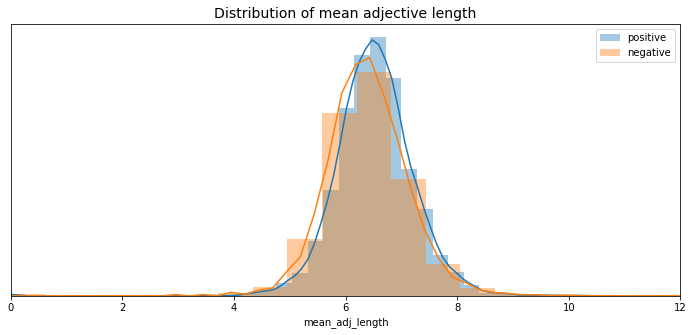

In [177]:
plt.figure(figsize=(12,5))
plt.title('Distribution of mean adjective length',fontsize=14)
sns.distplot(all_data[all_data['is_positive']==1]['mean_adj_length'],label='positive')
sns.distplot(all_data[all_data['is_positive']==0]['mean_adj_length'],label='negative')
plt.yticks(ticks=[])
plt.xlim(0,12)
plt.legend()

    Clearly, the mean adjective length in a given article irrespective of positive or not is around 6.2 letters. However, the distribution remains same for both negative & positive articles so this might not be a very good predictor

In [105]:
print(all_data['actual_heading'][556])
print(all_data['actual_heading'][655])


Transforming 120 acres of barren land into a self-sufficient organic farm: The story of Rajesh Naik and Oddoor farms
Watch how this American musician modified the clarinet to play Indian classical music!


In [106]:
print(pos_sentence('Transforming 120 acres of barren land into a self-sufficient organic farm: The story of Rajesh Naik and Oddoor farms'))
print(pos_sentence('Watch how this American musician modified the clarinet to play Indian classical music!'))


VBG CD NNS IN NN NN IN DT JJ JJ NN DT NN IN NNP NNP CC NNP NNS
VB WRB DT JJ NN VBD DT NN TO VB JJ JJ NN


    Heading plays a very important role in determining the article's positivity. If you notice the above heartwarming and not very heartwarming article, there are many common pos tags and this is the exact reason why it becomes hard to differentiate

In [107]:
print(max(all_data[all_data['is_positive']==1]['heading_sentiment']),min(all_data[all_data['is_positive']==1]['heading_sentiment']))
print(max(all_data[all_data['is_positive']==0]['heading_sentiment']),min(all_data[all_data['is_positive']==0]['heading_sentiment']))

0.875 -0.75
0.875 -0.875


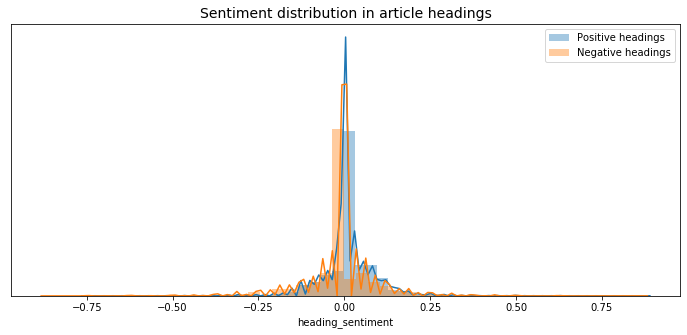

In [109]:
plt.figure(figsize=(12,5))
plt.title('Sentiment distribution in article headings',fontsize=14)
sns.distplot(all_data[all_data['is_positive']==1]['heading_sentiment'],label='Positive headings')
sns.distplot(all_data[all_data['is_positive']==0]['heading_sentiment'],label='Negative headings')
plt.yticks(ticks=[])
plt.legend()


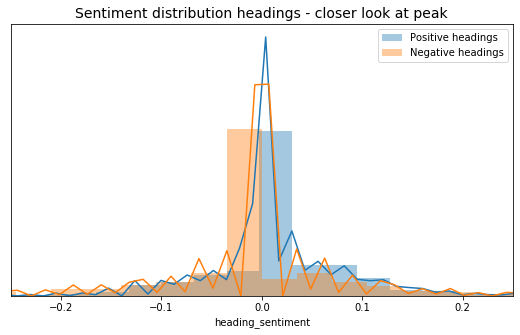

In [110]:
plt.figure(figsize=(9,5))
plt.title('Sentiment distribution headings - closer look at peak',fontsize=14)
sns.distplot(all_data[all_data['is_positive']==1]['heading_sentiment'],label='Positive headings')
sns.distplot(all_data[all_data['is_positive']==0]['heading_sentiment'],label='Negative headings')
plt.yticks(ticks=[])
plt.xlim(-.25,.25)
plt.legend()


    Though sentiments are extended to extremes, such cases are almost negligable. We can see a clear overlap between the negative and positive sentiments(understandably). On checking articles randomly, we noticed that the kinds of pos tags in both is similar and hence the overlapping distribution 

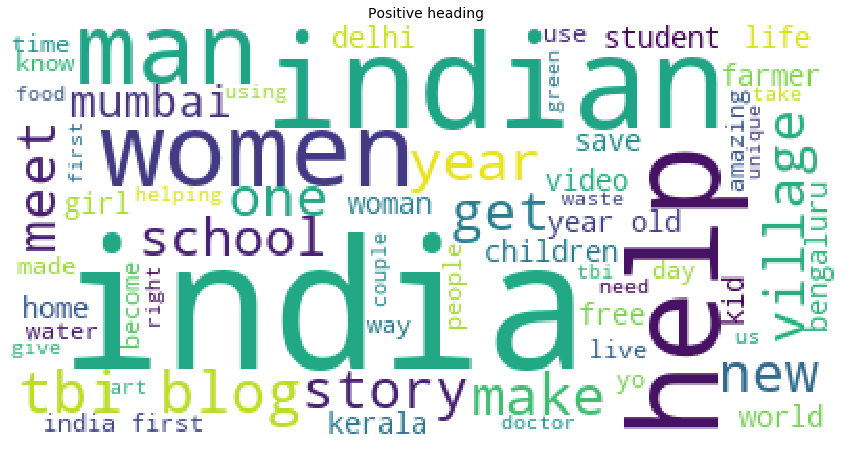

In [119]:
wc = WordCloud(background_color='white',min_font_size=10,stopwords=englishStopWords)
plt.figure(figsize=(15,12))
plt.axis('off')
plt.title('Positive heading',fontsize=14)
plt.imshow(wc.generate(' '.join(all_data[all_data['is_positive']==1]['lemmatized_heading'].values)))
#most articles are about help, change, women, cleanliness, inspiration and ingenious & indigenous

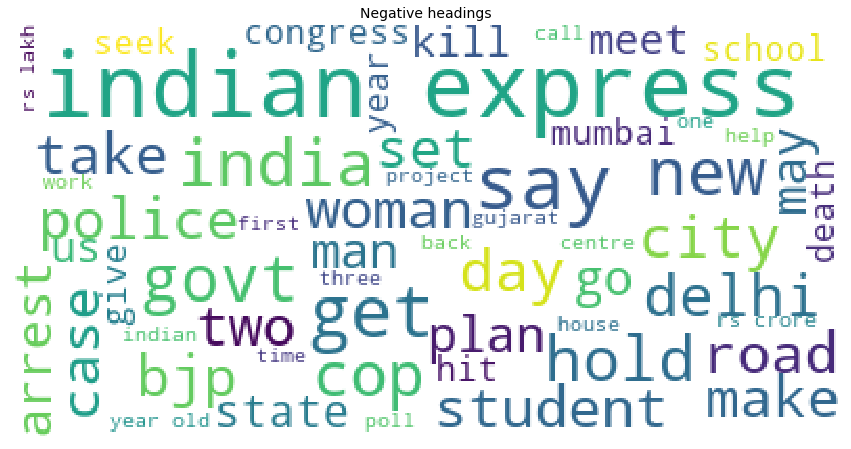

In [118]:
plt.figure(figsize=(15,12))
plt.axis('off')
plt.title('Negative headings',fontsize=14)
plt.imshow(wc.generate(' '.join(all_data[all_data['is_positive']==0]['lemmatized_heading'].values)))
#looks like most articles are about politics, accidents, law, death/crime and terrorism

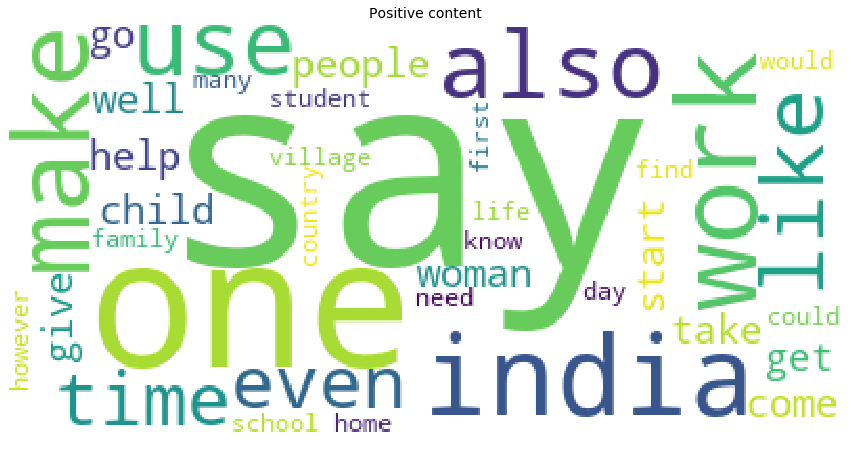

In [117]:
plt.figure(figsize=(15,12))
plt.axis('off')
plt.title('Positive content',fontsize=14)
plt.imshow(wc.generate(' '.join(all_data[all_data['is_positive']==1]['lemmatized_content'].values)))

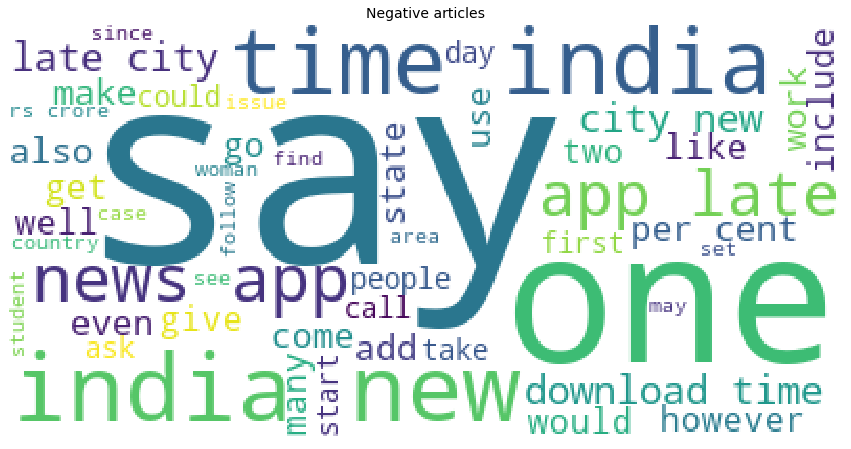

In [120]:
plt.figure(figsize=(15,12))
plt.axis('off')
plt.title('Negative articles',fontsize=14)
plt.imshow(wc.generate(' '.join(all_data[all_data['is_positive']==0]['lemmatized_content'].values)))

In [74]:
pn = [0,1]
#top 30 words before removing stopwords - positve and negative articles
for state in pn:
    word_list = ' '.join(all_data[all_data['is_positive']==state]['clean_content'].values).split()
    top_30_words_stop = pd.value_counts(word_list)
    print('{}:\n{}'.format(state,top_30_words_stop[:31]))


0:
the     555652
of      239522
to      227050
and     201389
in      179060
a       168670
for      92702
on       85333
is       80081
that     77511
was      64537
said     56028
with     52957
has      47707
from     47346
at       46370
be       46142
by       45584
as       45249
have     44288
The      42617
it       40988
he       39550
are      39548
will     37025
not      36562
had      35400
his      31477
an       29103
were     27289
been     26838
dtype: int64
1:
the      201601
to       118957
and      111990
of       110056
a         87632
in        78571
is        44047
for       38931
that      36734
with      28266
was       27336
on        23978
The       23968
are       21839
from      21509
as        19749
by        19416
their     18156
I         18075
have      17329
has       17303
it        17021
at        16450
be        15826
this      15729
an        15591
his       14793
he        14113
her       13635
also      13191
not       12635
dtype: int64


    Not at all helpful, since most of those are common words for every day speech - the,a,that,an,with... we did not remove stopwords intentionally to show their domination in text
    
    Since most part of any text is stopwords, to gain value out of the text we should first remove all stopwords

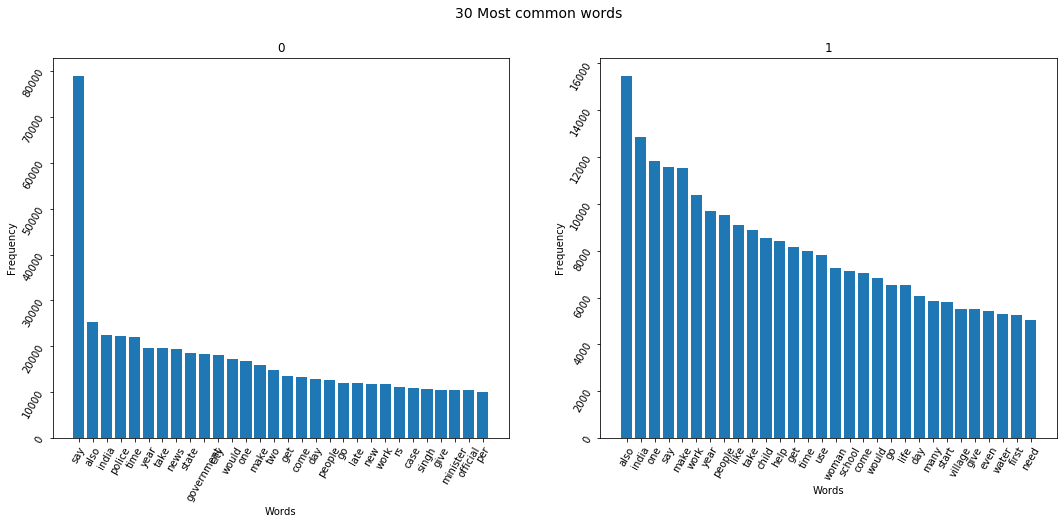

In [161]:
fig, axs = plt.subplots(nrows=1,ncols=2,figsize=(18,7))
fig.suptitle('30 Most common words',fontsize=14)

#faster way to remove stopwords, almost twice as fast as cached process because dictionaries work faster
stop_words_dict = pd.value_counts(englishStopWords)
pn = [0,1]
for state in pn:
    word_list = ' '.join(all_data[all_data['is_positive']==state]['lemmatized_content'].values).split()
    temp_no_stop = [word for word in word_list if word not in stop_words_dict]
    top_30_words_no_stop = pd.value_counts(temp_no_stop)
    ax = axs[state]
    ax.bar(top_30_words_no_stop.keys()[:30],top_30_words_no_stop[:30])
    ax.set_title(state)
    ax.set_xlabel('Words')
    ax.set_ylabel('Frequency')
    ax.tick_params(rotation=60)
    


    Some words are used more than others, we can check if that would be of use later by constructing a countvector

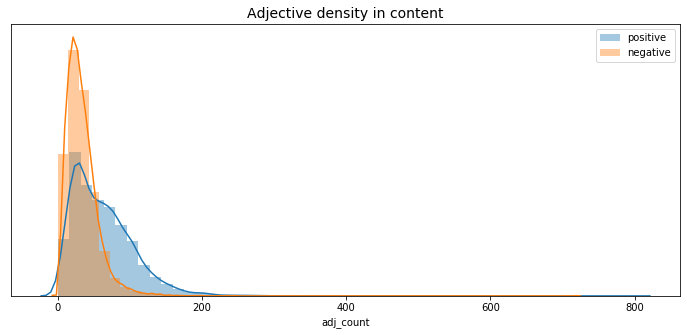

In [163]:
plt.figure(figsize=(12,5))
plt.title('Adjective density in content',fontsize=14)
sns.distplot(all_data[all_data['is_positive']==1]['adj_count'],label='positive')
sns.distplot(all_data[all_data['is_positive']==0]['adj_count'],label='negative')
plt.yticks(ticks=[])
plt.legend()


    This doesn't make much sense because we would like to understand density with respect to the overall words in a given article. So, let's look at the normalized adjective density

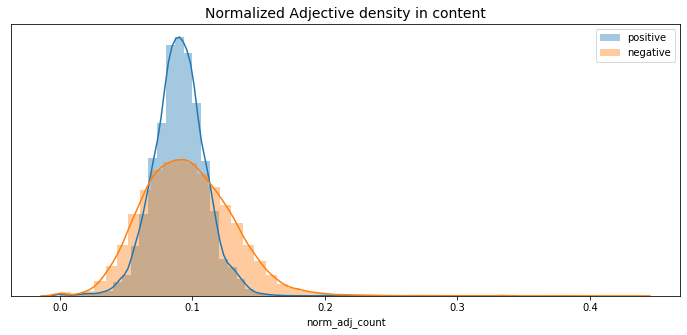

In [164]:
plt.figure(figsize=(12,5))
plt.title('Normalized Adjective density in content',fontsize=14)
sns.distplot(all_data[all_data['is_positive']==1]['norm_adj_count'],label='positive')
sns.distplot(all_data[all_data['is_positive']==0]['norm_adj_count'],label='negative')
plt.yticks(ticks=[])
plt.legend()

In [104]:
print('Mean Norm_adjective count in positive articles: ',np.mean(all_data[all_data['is_positive']==1]['norm_adj_count']))
print('std Norm_adjective count in positive articles: ',np.std(all_data[all_data['is_positive']==1]['norm_adj_count']))
print('Mean Norm_adjective count in negative articles: ',np.mean(all_data[all_data['is_positive']==0]['norm_adj_count']))
print('std Norm_adjective count in negative articles: ',np.std(all_data[all_data['is_positive']==0]['norm_adj_count']))
#can consider the feature

Mean Norm_adjective count in positive articles:  0.09004927053874787
std Norm_adjective count in positive articles:  0.019909608872194454
Mean Norm_adjective count in negative articles:  0.09618027747353856
std Norm_adjective count in negative articles:  0.03416253115370078


    Now we can see a clear distinction between the density of adjectives used in positive & negative articles and the mean, std also prove our statement worthy with significant difference in the values. So we can use normalized_adjective_count as a feature in our model

In [214]:
all_adjective_counts = pd.value_counts(' '.join(all_data['all_adjs'].values).split())

Text(0, 0.5, 'frequency')

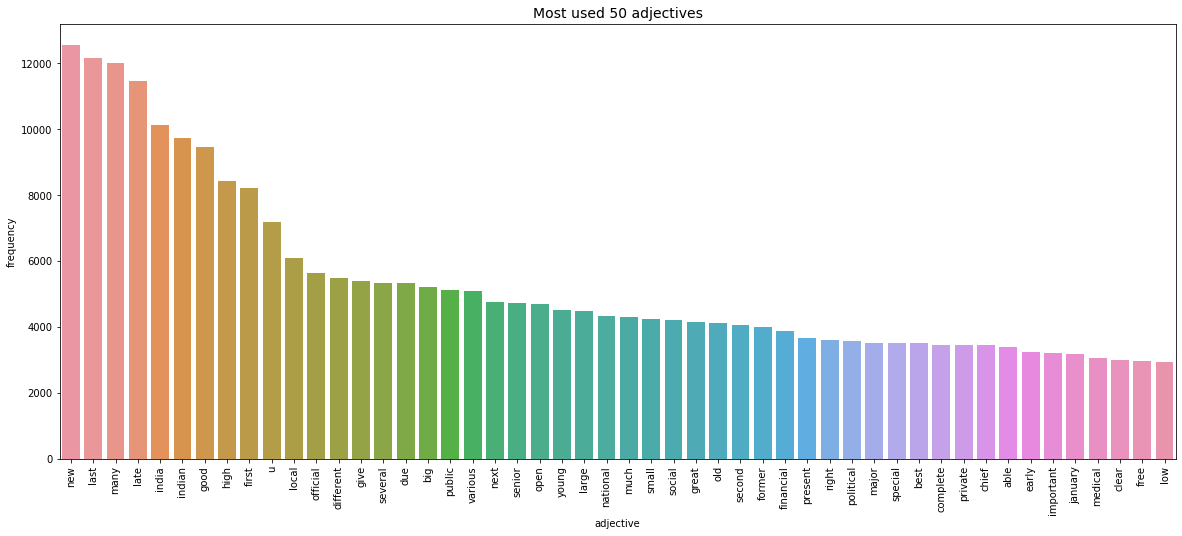

In [215]:
plt.figure(figsize=(20,8))
plt.title('Most used 50 adjectives',fontsize=14)
sns.barplot(all_adjective_counts[:50].keys(),all_adjective_counts[:50].values)
plt.xticks(rotation=90)
plt.xlabel('adjective')
plt.ylabel('frequency')


    Most used adjectives irrespective of the sentiment. Let's look at the most negative and positive words seperately for better understanding

In [228]:
def sentiment_score(word):
    lemma = lemmatizer.lemmatize(word, pos=wn.ADJ)
    if not lemma:
        return 0

    synsets = wn.synsets(lemma, pos=wn.ADJ)
    if not synsets:
        return 0

        # The most commonly used form of the word
    synset = synsets[0]
    swn_synset = swn.senti_synset(synset.name())

    return swn_synset.pos_score() - swn_synset.neg_score()


adj_df = pd.DataFrame()
adj_df['adj'] = list(all_adjective_counts.keys())
adj_df['count'] = all_adjective_counts.values
adj_df['sentiment'] = adj_df['adj'].apply(sentiment_score)

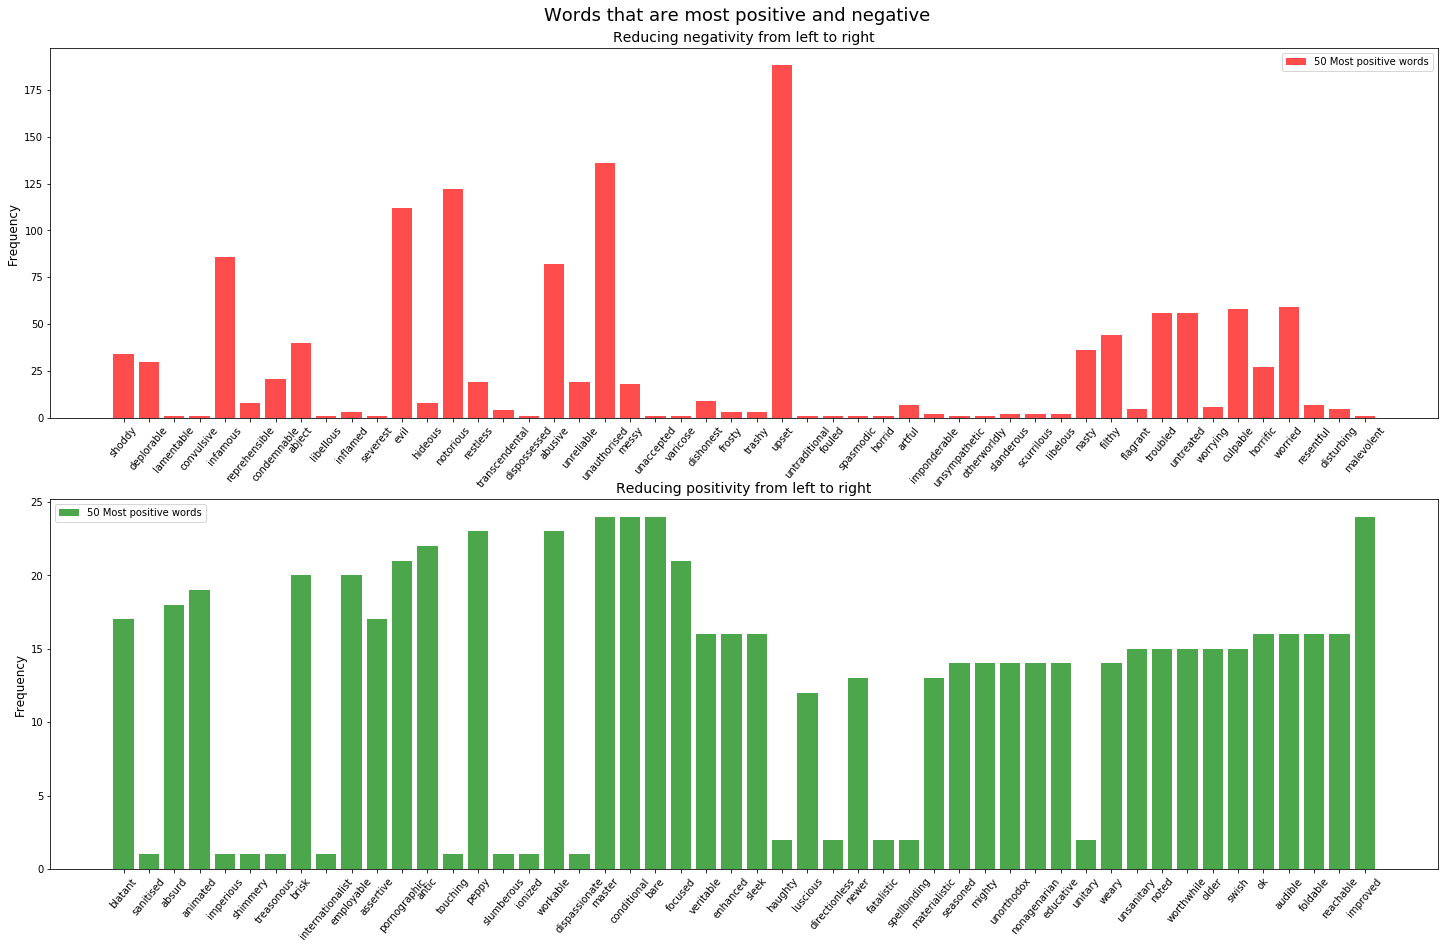

In [262]:
temp_neg = adj_df[adj_df['sentiment']<-.3].sort_values(by='sentiment')
temp_pos = adj_df[adj_df['sentiment']>.3].sort_values(by='sentiment')
fig, ax = plt.subplots(2,1,figsize=(20,12))
ax = ax.flatten()
plt.suptitle('Words that are most positive and negative',fontsize=18,y=1.03)
plt.tight_layout(h_pad=6)
ax[0].bar(temp_neg['adj'][:50],temp_neg['count'][:50],color='red',label='50 Most positive words',alpha=0.7)
ax[0].tick_params(axis='x',rotation=50)
ax[0].set_title('Reducing negativity from left to right',fontsize=14)
ax[0].set_ylabel('Frequency',fontsize=12)
ax[0].legend()
ax[1].bar(temp_pos['adj'][1:51],temp_pos['count'][1:51],color='green',label='50 Most positive words',alpha=0.7)
ax[1].tick_params(axis='x',rotation=50)
ax[1].set_title('Reducing positivity from left to right',fontsize=14)
ax[1].set_ylabel('Frequency',fontsize=12)
ax[1].legend()

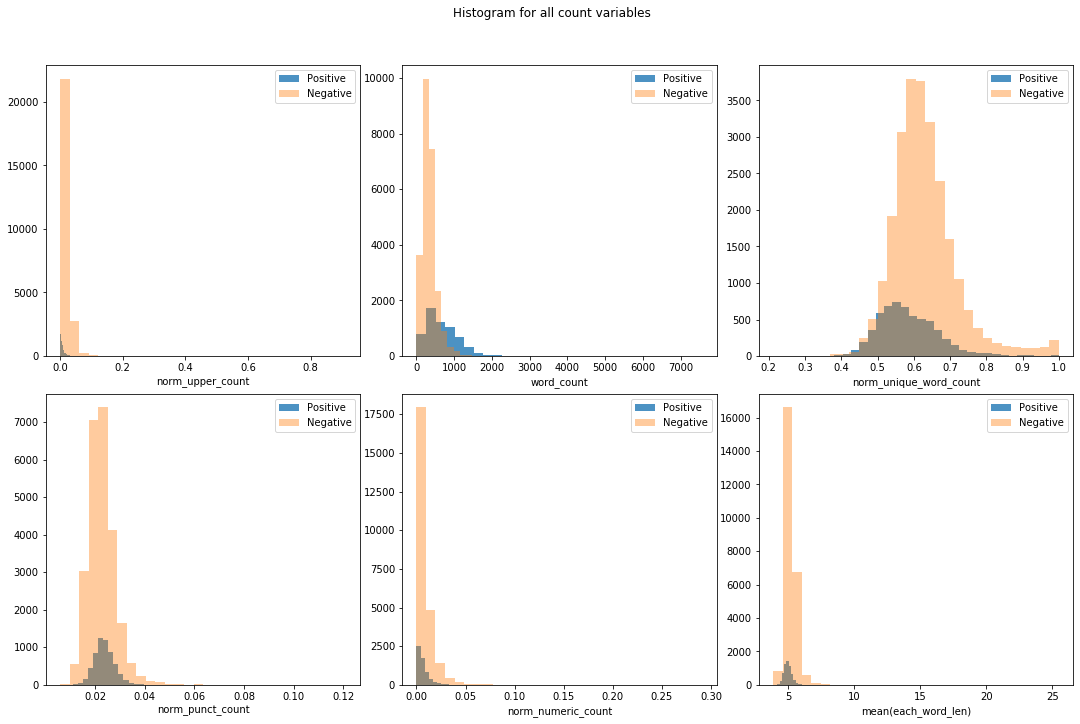

In [111]:
#histogram for the count variables
cols = ['norm_upper_count','word_count','norm_unique_word_count','norm_punct_count','norm_numeric_count','mean(each_word_len)']
fig,ax = plt.subplots(nrows=2,ncols=3,figsize=(15,10))
fig.suptitle('Histogram for all count variables')
fig.tight_layout(h_pad=2)
fig.subplots_adjust(top=0.9)
ax = ax.flatten()


for i,col in zip(range(len(cols)),cols):
    #ax.set_color_cycle(colors)
    ax[i].hist(all_data[all_data['is_positive']==1][col],bins=30,alpha=0.8,label='Positive')
    ax[i].hist(all_data[all_data['is_positive']==0][col],bins=30,alpha=0.4,label='Negative')
    ax[i].set_xlabel(col)
    ax[i].legend()

    There is obvious distinction between the positive and negative articles in most of the count variables. So we can use them in our model. However, for norm_punct_count and norm_numeric_count the distribution shape is exactly same, that can mean the distinction is only because of the quantity of data in each class.

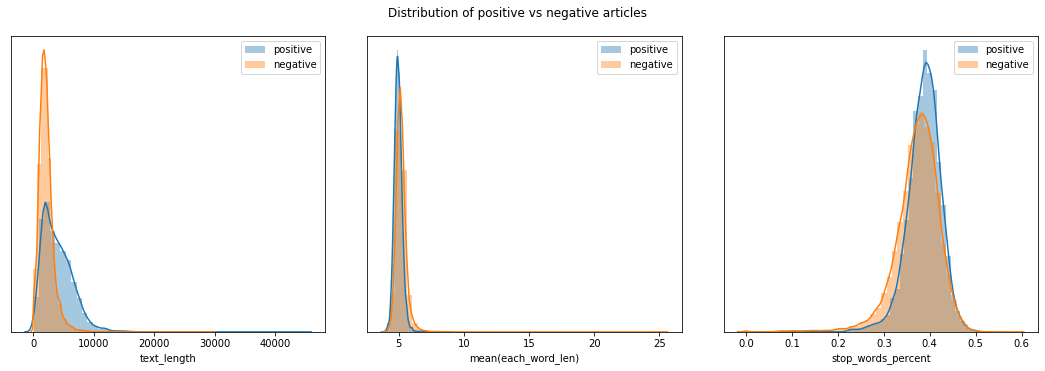

In [264]:
#distplots for few variables
dist_cols = ['text_length','mean(each_word_len)','stop_words_percent']
fig,ax = plt.subplots(nrows=1,ncols=3,figsize=(15,5))
fig.suptitle('Distribution of positive vs negative articles')
fig.tight_layout(h_pad=2)
fig.subplots_adjust(top=0.9)
ax = ax.flatten()
for i,col in zip(range(len(dist_cols)),dist_cols):
    sns.distplot(all_data[all_data['is_positive']==1][col],ax=ax[i],label='positive')
    sns.distplot(all_data[all_data['is_positive']==0][col],ax=ax[i],label='negative')
    ax[i].set_xlabel(col)
    ax[i].legend()
    ax[i].set_yticks(ticks=[])
    

    Average text length of positive articles seems to vary more than that of negative articles. Ironically stop_words_percent is greater for the positive articles, this could mean the additional text_length in positive articles is because of extensive usage of stop words. Let's look at the peaks closely 

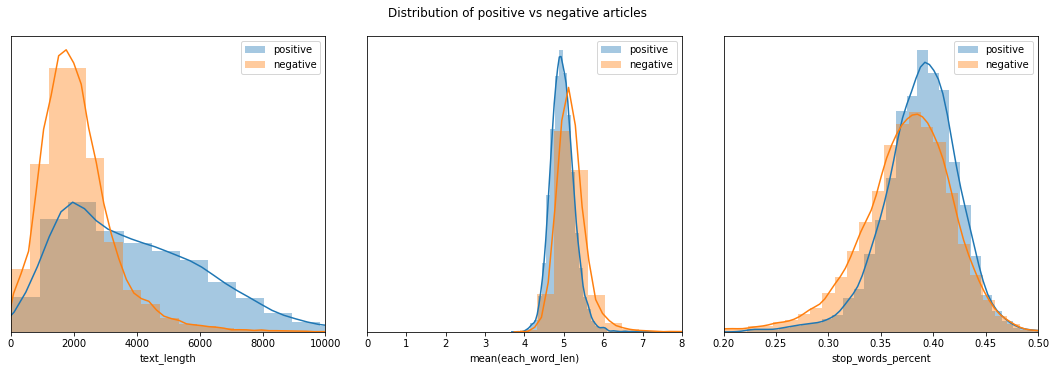

In [265]:
dist_cols = ['text_length','mean(each_word_len)','stop_words_percent']
fig,ax = plt.subplots(nrows=1,ncols=3,figsize=(15,5))
fig.suptitle('Distribution of positive vs negative articles')
fig.tight_layout(h_pad=2)
fig.subplots_adjust(top=0.9)
ax = ax.flatten()
for i,col in zip(range(len(dist_cols)),dist_cols):
    sns.distplot(all_data[all_data['is_positive']==1][col],ax=ax[i],label='positive')
    sns.distplot(all_data[all_data['is_positive']==0][col],ax=ax[i],label='negative')
    ax[i].set_xlabel(col)
    ax[i].legend()
    ax[i].set_yticks(ticks=[])
    if col == 'text_length':
        ax[i].set_xlim(0,10000)
    elif col == 'mean(each_word_len)':
        ax[i].set_xlim(0,8)
    else:
        ax[i].set_xlim(0.2,0.5)

In [113]:
all_data[all_data['text_length']>10000].index

Int64Index([15426,  5871,  3650,  5915,  6000,  1985,  5461,  8806,  4029,
            31065,
            ...
              683, 21808,  6609,  2882,   901, 17604,  5770,  2920,  1832,
             1330],
           dtype='int64', length=171)

    There are around 170 articles having more than 10k characters, afer a random check it seems they aren't bogus
    Now, we have a clear picture - distinction in text_length could still be useful but the others don't seem very encouraging

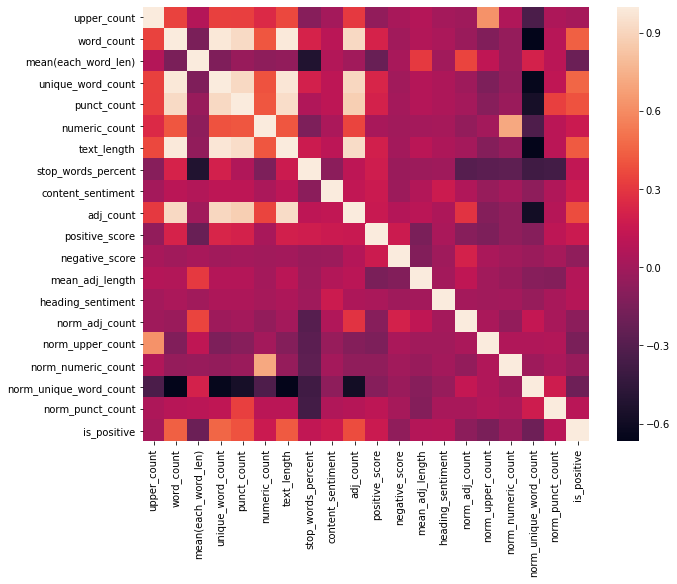

In [266]:
#word_count is very positively corelated to  many features
#interestingly mean_word_len and numeric_count are negatively corelated to stop_words_percent
#corelation of the target to any variable is very small or even 0. Given the volume and distinguishability of data it makes sense
#positive score - distance from most used adjectives to "good", negative score - distance from most used adjectives to "bad"
#no relation at all with any variables for positive and negative scores
plt.figure(figsize=(10,8))
plt.xticks(rotation=90)
sns.heatmap(all_data.corr())


## Content pos

#### We convert all of the content into pos tags to check the occurances of certain pos-tags together and the effect they have on the positivity of the article

In [267]:
count_vec = CountVectorizer()
pos_count_df = count_vec.fit_transform(all_data['pos_content'])
pos_count_df = pd.DataFrame(data = pos_count_df.toarray() , columns = count_vec.get_feature_names())
pos_count_df['is_positive'] = all_data['is_positive']
pos_count_df.head()

,cc,cd,dt,ex,fw,in,jj,jjr,jjs,md,nn,nnp,nnps,nns,pdt,pos,prp,rb,rbr,rbs,rp,sym,to,uh,vb,vbd,vbg,vbn,vbp,vbz,wdt,wp,wrb,is_positive
0,0,7,3,0,0,4,63,0,1,0,132,0,0,5,0,3,0,14,0,0,0,0,0,0,13,3,0,1,18,2,0,0,0,1.0
1,3,9,3,0,0,9,38,1,0,5,115,49,1,4,0,0,15,29,0,0,3,0,0,0,12,2,8,1,34,2,0,0,1,1.0
2,2,2,4,0,0,9,55,1,0,2,103,20,0,3,0,0,6,16,0,0,0,0,0,0,5,5,3,2,19,1,2,1,0,1.0
3,0,7,5,0,0,6,21,0,0,3,81,44,0,4,0,0,13,11,1,0,0,0,0,0,13,2,1,0,8,5,0,0,1,1.0
4,0,5,0,0,3,9,41,0,1,1,133,1,0,10,0,3,0,10,0,0,0,0,0,0,5,2,1,1,14,3,0,0,0,1.0


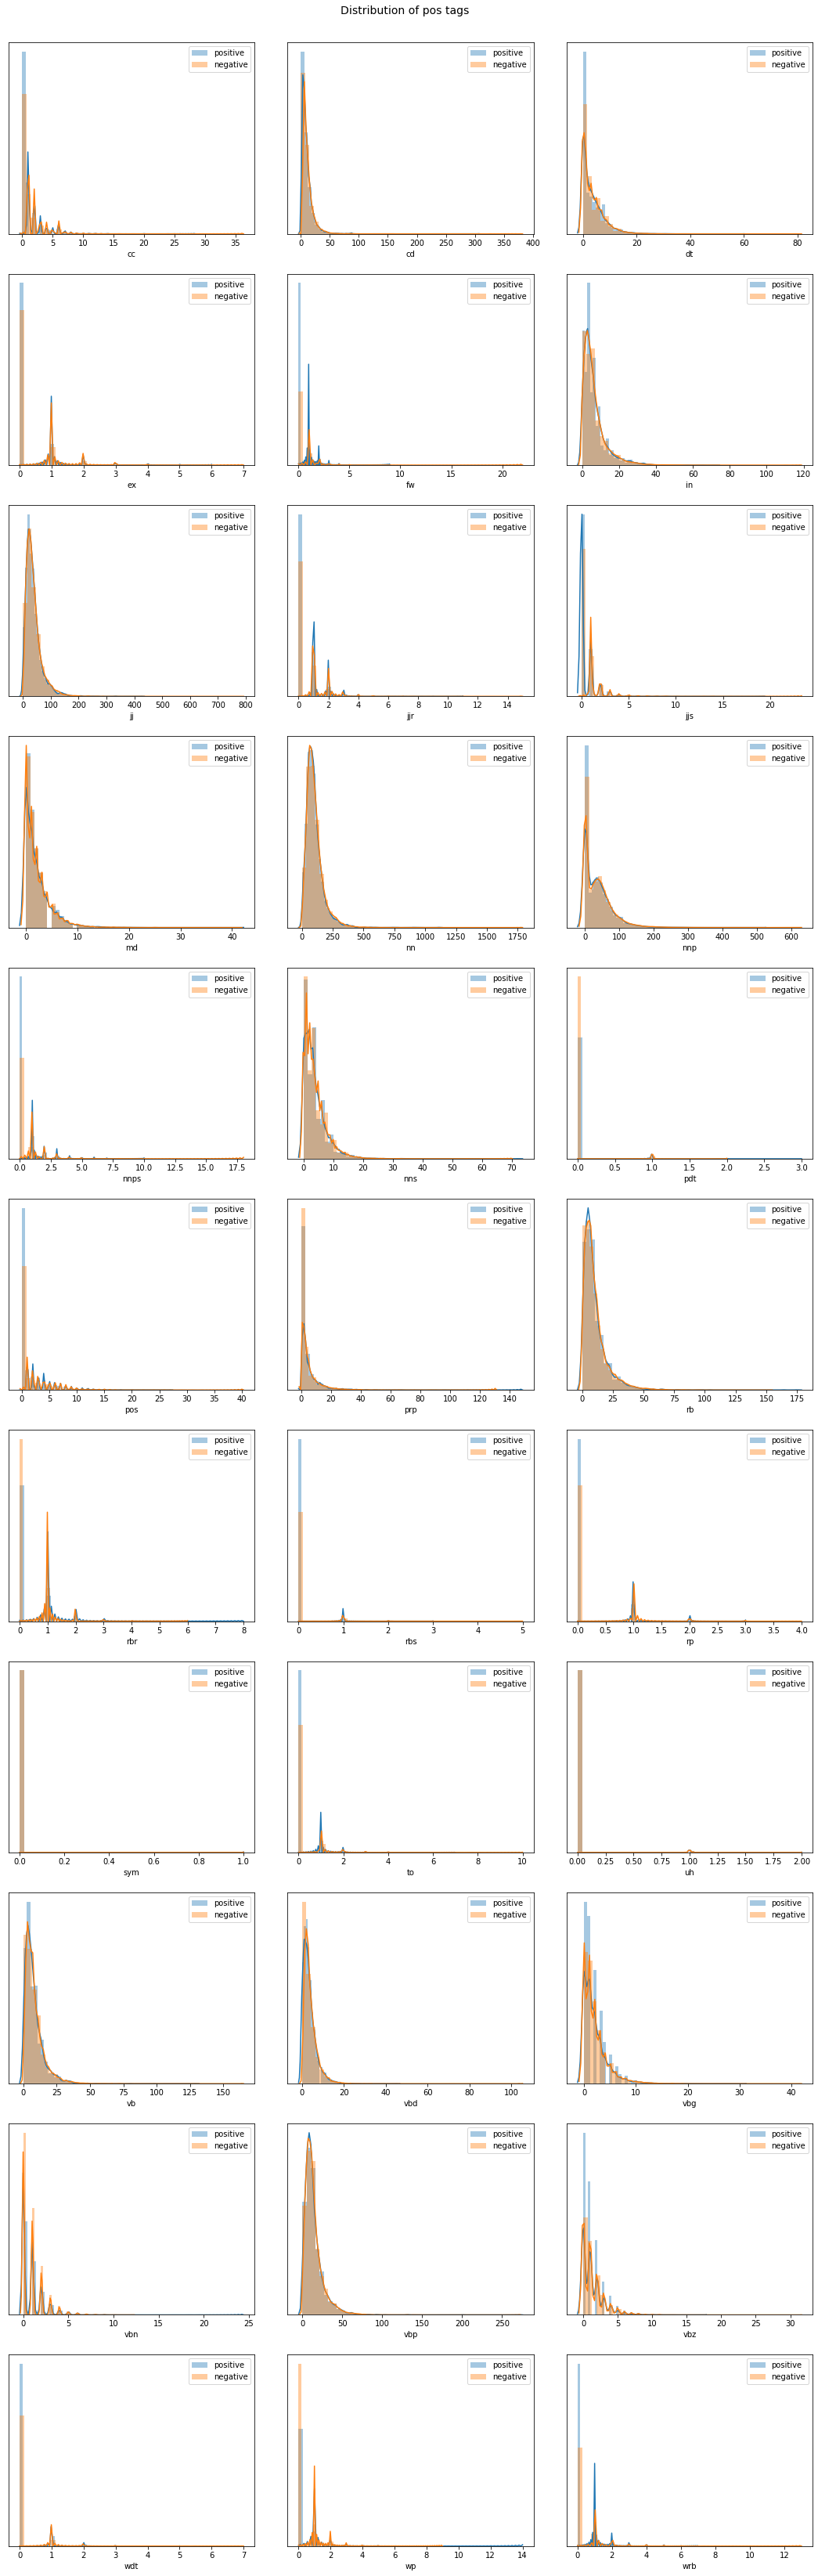

In [275]:
fig, axs = plt.subplots(nrows=11,ncols=3,figsize=(15,45))
axs = axs.flatten()
fig.suptitle('Distribution of pos tags',fontsize=14,y=1.01)
fig.tight_layout(h_pad=3)
col_list = list(pos_count_df.columns[:-1])
for ax,col in zip(axs,col_list):
    sns.distplot(pos_count_df[pos_count_df['is_positive']==1][col],ax=ax,label='positive')
    sns.distplot(pos_count_df[pos_count_df['is_positive']==0][col],ax=ax,label='negative')
    ax.set_xlabel(col)
    ax.set_yticks(ticks=[])
    ax.legend()

    These are all potential variables before looking through a filtering glass, now that we have seen distributions we can take a closer look at features that actually show some visible difference between positive and negative class. There doesn't seem any clear difference

In [276]:
count_vec = CountVectorizer(ngram_range=(2,3),max_features=300)
pos_count_df = count_vec.fit_transform(all_data['pos_content'])
pos_count_df = pd.DataFrame(data = pos_count_df.toarray() , columns = count_vec.get_feature_names())
pos_count_df['is_positive'] = all_data['is_positive']
pos_count_df.head()

,cc nn,cd cd,cd cd nn,cd in,cd in nn,cd jj,cd jj nn,cd nn,cd nn cd,cd nn jj,cd nn nn,cd nn nnp,cd nn rb,cd nnp,cd nnp nn,cd nnp nnp,cd nns,dt jj,dt jj nn,dt nn,dt nn jj,dt nn nn,dt nnp,dt nnp nnp,in cd,in cd nn,in jj,in jj jj,in jj nn,in nn,in nn jj,in nn nn,in nn nnp,in nnp,in nnp nnp,in prp,jj cd,jj cd nn,jj in,jj jj,jj jj jj,jj jj nn,jj jj nnp,jj nn,jj nn cd,jj nn dt,jj nn in,jj nn jj,jj nn md,jj nn nn,jj nn nnp,jj nn nns,jj nn pos,jj nn prp,jj nn rb,jj nn vb,jj nn vbd,jj nn vbg,jj nn vbp,jj nnp,jj nnp nn,jj nnp nnp,jj nns,jj nns vbp,jj rb,jj vb,jj vbg,jj vbp,jj vbp jj,jjs nn,md rb,md vb,md vb jj,md vb nn,md vb vb,nn cc,nn cd,nn cd cd,nn cd jj,nn cd nn,nn dt,nn dt jj,nn dt nn,nn in,nn in cd,nn in jj,nn in nn,nn in nnp,nn jj,nn jj cd,nn jj jj,nn jj nn,nn jj nnp,nn jj nns,nn md,nn md vb,nn nn,nn nn cd,nn nn dt,nn nn in,...,nnp vbp nnp,nnp vbz,nns jj,nns jj nn,nns nn,nns nnp,nns rb,nns vbp,nns vbp jj,nns vbp nn,pos jj,pos jj nn,pos nn,pos nn nn,prp jj,prp nn,prp rb,prp rb vbp,prp vbd,prp vbp,prp vbp jj,prp vbp nn,rb cd,rb cd nn,rb in,rb jj,rb jj jj,rb jj nn,rb jj nnp,rb nn,rb nn jj,rb nn nn,rb nnp,rb nnp nnp,rb rb,rb rb jj,rb vb,rb vb jj,rb vb nn,rb vbd,rb vbp,rb vbp jj,rb vbp nn,rb vbz,vb cd,vb jj,vb jj jj,vb jj nn,vb nn,vb nn jj,vb nn nn,vb nn nnp,vb nnp,vb nnp nnp,vb rb,vb vb,vbd cd,vbd dt,vbd jj,vbd jj jj,vbd jj nn,vbd nn,vbd nn nn,vbd nnp,vbd rb,vbg jj,vbg jj nn,vbg nn,vbg nn nn,vbg nnp,vbn jj,vbn nn,vbp cd,vbp cd nn,vbp dt,vbp dt nn,vbp in,vbp jj,vbp jj jj,vbp jj nn,vbp jj nnp,vbp nn,vbp nn jj,vbp nn nn,vbp nn nnp,vbp nn rb,vbp nn vbp,vbp nnp,vbp nnp nn,vbp nnp nnp,vbp nns,vbp prp,vbp rb,vbp rb jj,vbp vb,vbp vbp,vbz jj,vbz jj nn,vbz nn,is_positive
0,0,0,0,0,0,2,1,4,0,1,2,0,1,0,0,0,1,0,0,3,1,1,0,0,0,0,3,0,2,1,0,1,0,0,0,0,1,1,0,16,0,15,0,41,1,0,2,3,0,18,0,0,1,0,2,4,2,0,6,0,0,0,1,1,1,0,0,1,1,0,0,0,0,0,0,0,2,0,0,1,2,0,2,3,0,2,1,0,20,0,4,15,0,0,0,0,68,1,2,1,...,0,0,3,0,0,0,0,2,2,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,5,3,2,0,1,1,0,0,0,2,1,2,1,1,0,3,1,1,0,2,4,0,3,4,1,2,0,0,0,1,0,1,0,1,1,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,7,4,3,0,7,2,3,0,0,1,0,0,0,0,0,0,0,2,1,1,0,0,1.0
1,0,0,0,2,1,1,0,3,0,0,2,0,1,1,1,0,1,1,1,1,0,1,0,0,0,0,0,0,0,2,0,0,1,4,2,1,2,0,0,1,0,1,0,24,0,0,0,2,0,9,5,0,0,1,4,1,0,0,1,3,1,0,1,0,0,1,2,1,0,0,1,4,0,4,0,1,2,0,0,2,0,0,0,2,0,0,1,1,12,0,0,7,1,1,1,1,43,1,0,1,...,0,1,0,0,0,0,1,2,1,0,0,0,0,0,2,0,1,0,0,8,3,0,1,0,1,7,0,3,0,6,1,2,4,1,1,0,0,0,0,0,6,2,3,1,0,2,0,1,6,0,2,2,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,1,1,0,0,0,1,0,2,0,3,6,0,5,1,7,0,5,1,0,0,1,1,0,1,3,1,0,4,1,0,0,1,1.0
2,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,1,1,2,1,1,0,0,0,0,3,1,2,3,0,3,0,1,0,0,0,0,1,14,3,9,0,34,0,2,1,5,0,18,1,0,0,2,2,0,0,0,2,1,0,0,2,2,1,0,0,1,0,0,1,1,1,0,0,2,0,0,0,0,2,1,1,6,0,2,1,1,18,0,5,10,0,2,0,0,49,0,0,5,...,0,0,0,0,0,0,0,3,1,0,0,0,0,0,0,1,3,1,0,2,1,1,1,0,0,6,1,4,1,1,0,1,1,1,1,0,1,0,1,1,2,2,0,1,0,1,0,1,3,0,2,0,0,0,0,0,0,0,2,1,1,0,0,0,1,1,0,1,0,0,0,1,0,0,0,0,2,6,1,5,0,4,1,1,0,0,2,4,1,1,0,0,1,1,1,0,0,0,0,1.0
3,0,0,0,0,0,2,1,3,1,0,2,0,0,1,0,0,0,1,1,1,0,0,3,1,0,0,0,0,0,2,0,1,0,2,0,2,0,0,1,3,0,3,0,11,0,0,1,0,0,3,5,0,0,2,0,0,0,0,0,5,3,1,1,1,0,0,0,0,0,0,1,2,1,1,0,0,5,0,1,3,2,0,1,2,0,0,2,0,3,0,1,2,0,0,2,2,41,3,1,0,...,0,0,1,0,2,0,0,1,0,1,0,0,0,0,0,0,1,0,2,3,2,0,0,0,1,5,1,2,1,1,0,0,0,0,1,1,1,0,0,0,0,0,0,2,0,1,0,0,5,0,2,1,3,2,1,1,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,2,1,1,0,2,0,2,0,0,0,0,0,0,0,1,0,0,0,1,2,1,1,1.0
4,0,0,0,0,0,0,0,4,0,2,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,1,2,1,0,1,0,0,0,0,0,0,0,5,0,4,0,32,0,0,2,4,0,21,0,1,1,0,2,0,0,0,0,0,0,0,0,0,1,1,0,1,0,1,0,1,0,1,0,0,2,0,0,1,0,0,0,7,0,3,1,0,18,0,2,16,0,0,1,1,78,0,0,3,...,0,0,2,2,1,0,0,5,2,2,1,1,1,0,0,0,0,0,0,0,0,0,2,2,0,4,1,2,0,0,0,0,0,0,1,0,1,0,1,0,1,0,1,1,0,1,0,1,3,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,1,0,0,2,4,1,2,0,7,0,4,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0,1.0


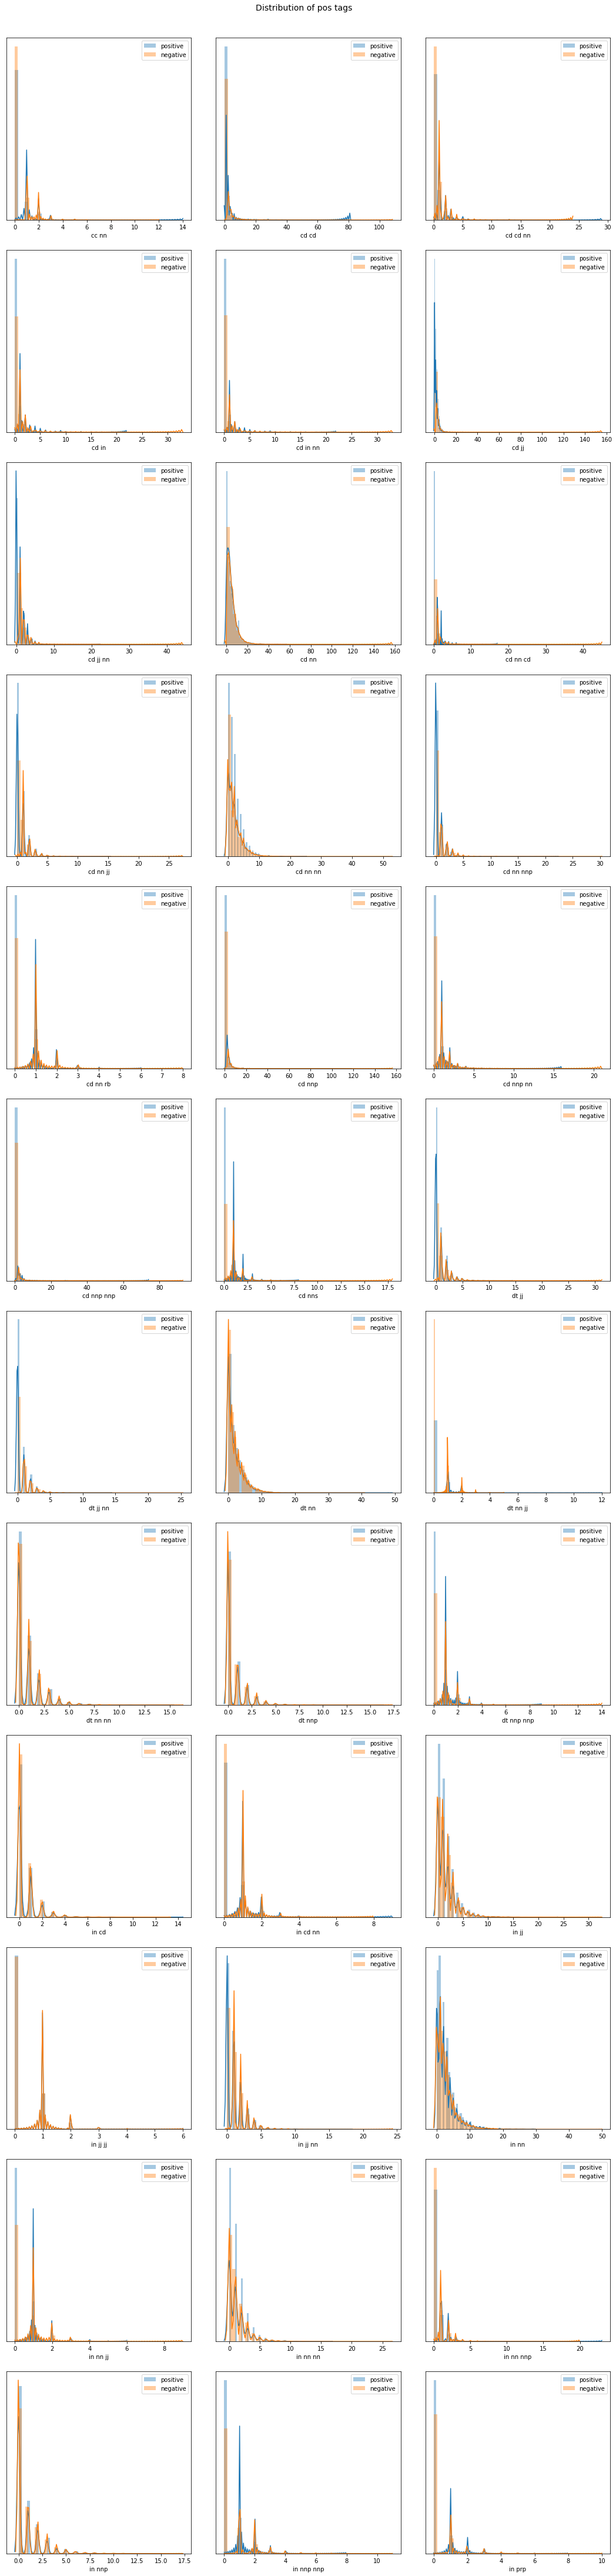

In [277]:
fig, axs = plt.subplots(nrows=12,ncols=3,figsize=(15,60))
axs = axs.flatten()
fig.suptitle('Distribution of pos tags',fontsize=14,y=1.01)
plt.tight_layout(h_pad=3)
col_list = list(pos_count_df.columns[:36])
for ax,col in zip(axs,col_list):
    sns.distplot(pos_count_df[pos_count_df['is_positive']==1][col],ax=ax,label='positive')
    sns.distplot(pos_count_df[pos_count_df['is_positive']==0][col],ax=ax,label='negative')
    ax.set_xlabel(col)
    ax.set_yticks(ticks=[])
    ax.legend()
    
#cd jj

    "cd jj" looks most promising in this set of features with a strong positive presence. Let's look at it

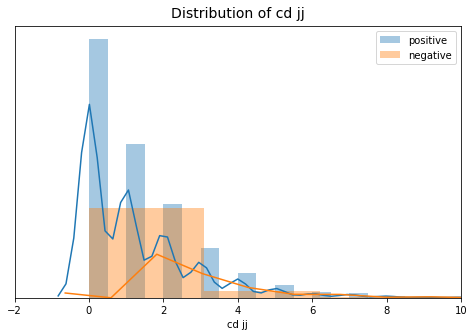

In [281]:
plt.figure(figsize=(8,5))
plt.title('Distribution of cd jj',fontsize=14,y=1.01)
sns.distplot(pos_count_df[pos_count_df['is_positive']==1]['cd jj'],label='positive')
sns.distplot(pos_count_df[pos_count_df['is_positive']==0]['cd jj'],label='negative')
plt.xlabel('cd jj')
plt.yticks(ticks=[])
plt.xlim(-2,10)
plt.legend()

    There it is! where negative articles have a flat surface, positive articles have a vertical zig-zag with a reducing trend towards the right. That is a good enough distinction to use in model

## Headings pos

#### Similar to the content pos, this time we convert the headings into pos tags and perform similar analysis

In [282]:
count_vec = CountVectorizer(ngram_range=(1,1))
pos_count_df_hd = count_vec.fit_transform(all_data['pos_heading'])
pos_count_df_hd = pd.DataFrame(data = pos_count_df_hd.toarray() , columns = count_vec.get_feature_names())
pos_count_df_hd['is_positive'] = all_data['is_positive']
pos_count_df_hd.head()

,cc,cd,dt,ex,fw,in,jj,jjr,jjs,md,nn,nnp,nnps,nns,pdt,pos,prp,rb,rbr,rbs,rp,to,uh,vb,vbd,vbg,vbn,vbp,vbz,wdt,wp,wrb,is_positive
0,0,0,0,0,0,0,1,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1.0
1,0,1,0,0,0,0,1,0,0,0,4,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1.0
2,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1.0
3,0,0,0,0,0,0,0,0,0,0,0,13,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0
4,0,0,0,0,0,0,1,0,1,0,2,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1.0


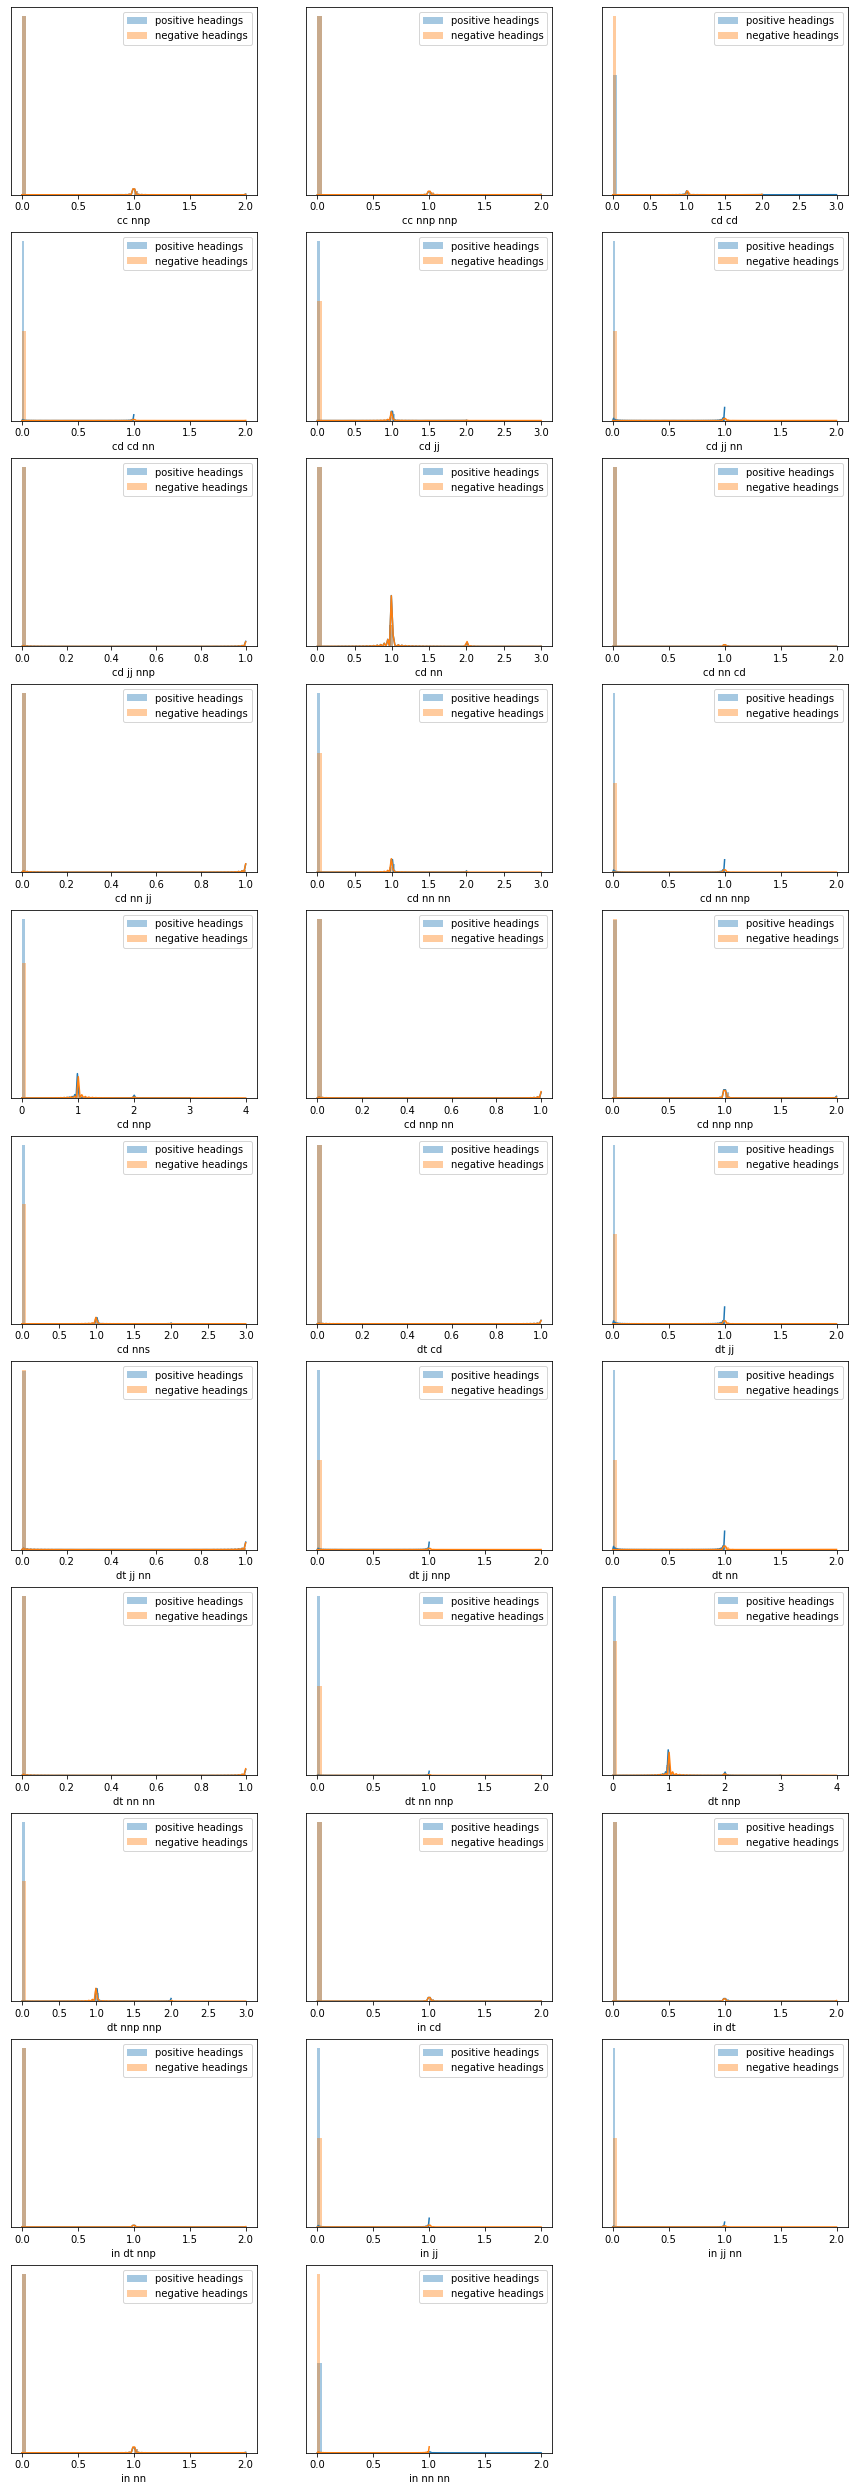

In [296]:
#Distribution of pos tags in headings
plt.figure(figsize=(15,45))
plt.tight_layout(h_pad=2)
col_list = list(pos_count_df_hd.columns[:-1])
for ax,col in zip(range(1,33),col_list):
    plt.subplot(11,3,ax)
    sns.distplot(pos_count_df_hd[pos_count_df_hd['is_positive']==1][col],label='positive headings')
    sns.distplot(pos_count_df_hd[pos_count_df_hd['is_positive']==0][col],label='negative headings')
    plt.xlabel(col)
    plt.yticks(ticks=[])
    plt.legend()
    


In [292]:
count_vec = CountVectorizer(ngram_range=(2,3),max_features=300)
pos_count_df_hd = count_vec.fit_transform(all_data['pos_heading'])
pos_count_df_hd = pd.DataFrame(data = pos_count_df_hd.toarray() , columns = count_vec.get_feature_names())
pos_count_df_hd['is_positive'] = all_data['is_positive']
pos_count_df_hd.head()

,cc nnp,cc nnp nnp,cd cd,cd cd nn,cd jj,cd jj nn,cd jj nnp,cd nn,cd nn cd,cd nn jj,cd nn nn,cd nn nnp,cd nnp,cd nnp nn,cd nnp nnp,cd nns,dt cd,dt jj,dt jj nn,dt jj nnp,dt nn,dt nn nn,dt nn nnp,dt nnp,dt nnp nnp,in cd,in dt,in dt nnp,in jj,in jj nn,in nn,in nn nn,in nn nnp,in nnp,in nnp nn,in nnp nnp,in prp,in vbg,jj cd,jj cd nn,jj jj,jj jj nn,jj jj nnp,jj nn,jj nn cd,jj nn jj,jj nn nn,jj nn nnp,jj nn nns,jj nn vb,jj nn vbd,jj nn vbp,jj nnp,jj nnp cd,jj nnp nn,jj nnp nnp,jj nns,jj nns vbp,jj vbp,jjs nn,md vb,md vb nn,md vb nnp,nn cd,nn cd nn,nn cd nnp,nn in,nn in nn,nn in nnp,nn jj,nn jj jj,nn jj nn,nn jj nnp,nn md,nn md vb,nn nn,nn nn cd,nn nn in,nn nn jj,nn nn nn,nn nn nnp,nn nn nns,nn nn rb,nn nn vb,nn nn vbd,nn nn vbp,nn nnp,nn nnp cd,nn nnp jj,nn nnp nn,nn nnp nnp,nn nnp rb,nn nnp vbp,nn nnp vbz,nn nns,nn nns vbp,nn prp,nn rb,nn rb jj,nn rb nn,...,nnps nnp nnp,nns in,nns jj,nns jj nn,nns nn,nns nn nn,nns nnp,nns nnp nnp,nns vbd,nns vbp,nns vbp jj,nns vbp nn,nns vbp nnp,pos nn,prp jj,prp md,prp md vb,prp nn,prp nnp,prp nnp nnp,prp vbd,prp vbp,prp vbp jj,prp vbz,rb cd,rb cd nn,rb jj,rb jj nn,rb jj nnp,rb nn,rb nn nn,rb nnp,rb nnp nn,rb nnp nnp,rb rb,rb vb,rb vbp,rb vbz,to nnp,to vb,vb cd,vb dt,vb jj,vb jj nn,vb jj nnp,vb nn,vb nn nn,vb nn nnp,vb nnp,vb nnp nn,vb nnp nnp,vb prp,vbd cd,vbd cd nn,vbd jj,vbd jj nn,vbd nn,vbd nn nn,vbd nnp,vbd nnp nn,vbd nnp nnp,vbg jj,vbg jj nn,vbg nn,vbg nn nn,vbg nnp,vbg nnp nnp,vbn nn,vbn nnp,vbp cd,vbp cd nn,vbp jj,vbp jj jj,vbp jj nn,vbp jj nnp,vbp nn,vbp nn jj,vbp nn nn,vbp nn nnp,vbp nnp,vbp nnp nn,vbp nnp nnp,vbp rb,vbp vb,vbp vbg,vbz cd,vbz dt,vbz jj,vbz jj nn,vbz nn,vbz nnp,vbz nnp nnp,vbz vbg,vbz vbg nnp,vbz wrb,wrb jj,wrb nnp,wrb nnp nnp,wrb prp,is_positive
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0
1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,2,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0


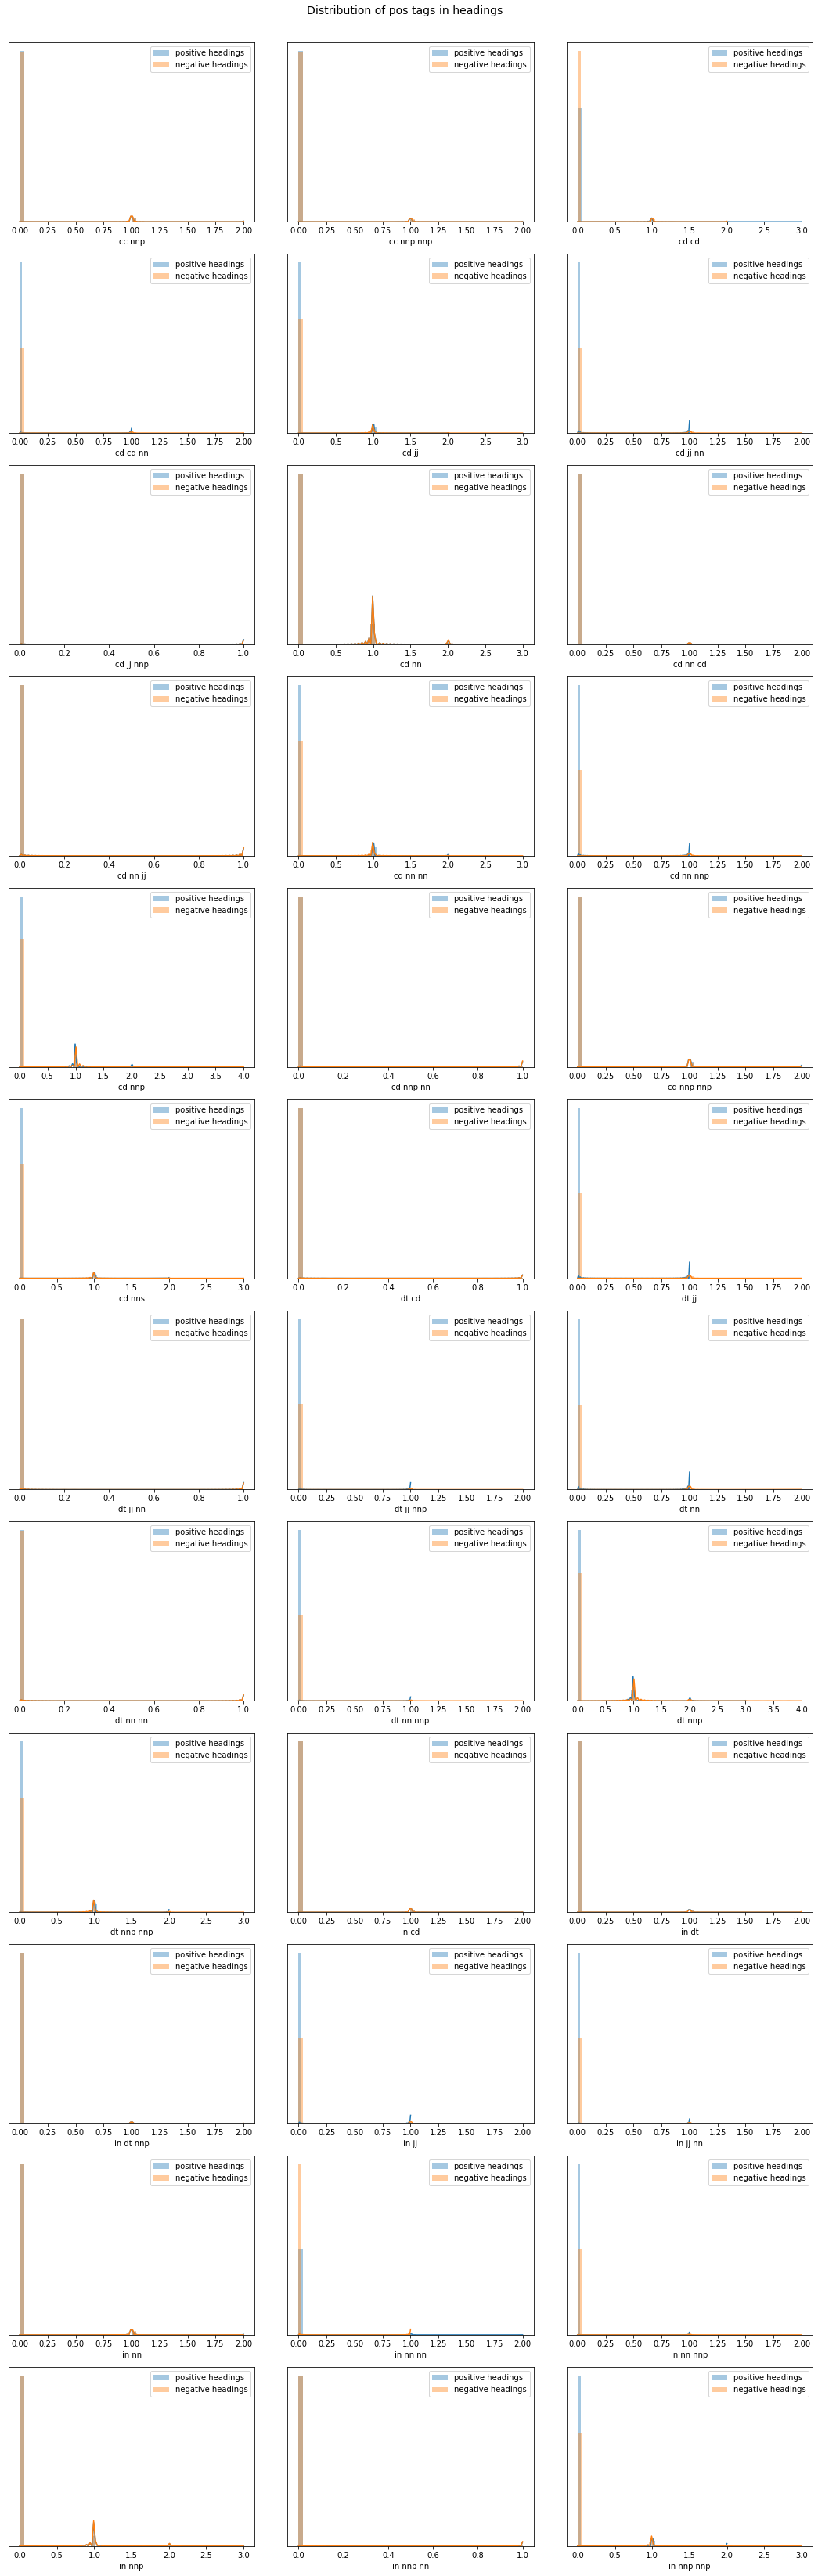

In [294]:
fig, axs = plt.subplots(nrows=12,ncols=3,figsize=(15,45))
axs = axs.flatten()
fig.suptitle('Distribution of pos tags in headings',fontsize=14,y=1.01)
fig.tight_layout(h_pad=2)
col_list = list(pos_count_df_hd.columns[:36])
for ax,col in zip(axs,col_list):
    sns.distplot(pos_count_df_hd[pos_count_df_hd['is_positive']==1][col],ax=ax,label='positive headings')
    sns.distplot(pos_count_df_hd[pos_count_df_hd['is_positive']==0][col],ax=ax,label='negative headings')
    ax.set_xlabel(col)
    ax.set_yticks(ticks=[])
    ax.legend()

#### POS distributions findings:

    1. Most of the tags and tag combinations have similar distribution for positive and negative articles. The ones that have distinction are very rare and they are helpful for our model
    2. There was an expectation that the heading sort of summarises most stories, but turns out these headings are note good enough storytellers for the computer to identify differences and hence leaving our expectation not so useful
    3. We have identified "cd jj" as a useful feature and hence will include it along side all other features choosen till now for modeling
    
*Till now the concentration has been on the pos tags, it will now shift to the actual words and their occurances. One useful way to understand how important words are to the target is a TFIDF, Let's go!*

## TFIDF

In [297]:
tfidf = TfidfVectorizer(ngram_range=(1,2),max_features=350)
tfidf_pos = TfidfVectorizer(ngram_range=(1,3),max_features=100)

In [298]:
tfidf_df = tfidf.fit_transform(all_data['lemmatized_content'])
tfidf_df = pd.DataFrame(data = tfidf_df.toarray() , columns = tfidf.get_feature_names())
tfidf_df['is_positive'] = all_data['is_positive']
tfidf_df.head()

,10,15,20,accord,accuse,across,act,action,add,after,ago,allow,along,already,also,always,among,and,another,app,app late,area,around,arrest,as,ask,attack,authority,away,back,bank,base,become,begin,believe,best,big,bjp,board,body,book,bring,business,but,call,carry,case,cause,cent,central,centre,change,charge,chief,child,city,city news,claim,class,close,college,come,committee,community,company,complete,conduct,congress,continue,cost,could,country,court,create,crore,day,deal,decide,decision,delhi,demand,department,development,different,director,district,do,download,download time,dr,due,early,education,election,end,ensure,even,event,every,expect,...,reach,read,receive,remain,report,resident,result,return,right,road,rs,run,say,school,second,secretary,sector,security,see,seek,send,senior,service,set,several,share,she,show,since,singh,six,small,so,social,society,soon,source,special,stand,start,state,station,step,still,story,student,study,support,system,take,talk,team,tell,test,the,there,they,thing,think,this,though,three,thursday,till,time,time india,today,train,try,turn,two,university,us,use,various,vehicle,village,visit,want,waste,water,way,we,week,well,when,while,with,within,without,woman,work,world,would,write,year,yet,you,young,is_positive
0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.051732,0.000000,0.0,0.0,0.000000,0.0,0.068217,0.000000,0.066876,0.000000,0.0,0.049509,0.050147,0.0,0.000000,0.0,0.000000,0.058088,0.000000,0.0,0.000000,0.061235,0.0,0.0,0.000000,0.070716,0.0,0.074446,0.068512,0.0,0.079223,0.295371,0.0,0.000000,0.000000,0.000000,0.0,0.151703,0.0,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,0.0,0.042875,0.051940,0.143632,0.0,0.0,0.000000,0.043475,0.0,0.0,0.0,0.000000,0.148343,0.0,0.213777,0.0,0.000000,0.000000,0.0,0.211081,0.0,0.139846,0.0,0.0,0.000000,0.0,0.0,0.067488,0.0,0.000000,0.0,0.0,0.143322,0.051386,0.051857,0.0,0.067430,0.0,0.0,0.0,0.000000,0.0,0.100864,0.000000,0.184685,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.066798,0.000000,0.0,0.0,0.168259,0.068478,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.06669,0.0,0.000000,0.0,0.058031,0.0,0.0,0.0,0.000000,0.0,0.00000,0.0,0.0,0.000000,0.0,0.000000,0.047958,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.038166,0.000000,0.065434,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.142153,0.000000,0.069062,0.0,0.0,0.000000,0.069566,0.049965,0.0,0.0,0.065327,0.000000,0.000000,0.0,0.0,0.104166,0.000000,0.00000,0.0,0.000000,0.058332,0.281785,0.000000,0.000000,0.000000,0.0,0.055682,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.072648,0.000000,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.073900,0.0,0.0,0.000000,0.0,0.068073,0.152479,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.082896,0.0,0.070450,0.366634,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.068367,0.0,0.000000,0.073687,0.0,0.000000,0.000000,0.173938,0.0,0.000000,0.0,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.071665,0.0,0.0,0.000000,0.043384,0.0,0.0,0.0,0.075415,0.000000,0.0,0.000000,0.0,0.162214,0.000000,0.0,0.000000,0.0,0.046517,0.0,0.0,0.078106,0.0,0.0,0.000000,0.0,0.068007,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.150977,0.000000,0.000000,0.075171,...,0.0,0.0,0.0,0.0,0.062838,0.000000,0.0,0.072799,0.066657,0.000000,0.0,0.0,0.251857,0.000000,0.0,0.0,0.0,0.0,0.058727,0.0,0.0,0.0,0.0,0.060519,0.00000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.077419,0.0,0.00000,0.0,0.0,0.000000,0.0,0.054671,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.114257,0.000000,0.195888,0.055045,0.335907,0.105170,0.0,0.131657,0.072288,0.212780,0.000000,0.068916,0.0,0.0,0.073045,0.034710,0.000000,0.0,0.0,0.065189,0.000000,0.178592,0.0,0.0,0.000000,0.000000,0.00000,0.0,0.000000,0.174628,0.000000,0.000000,0.058167,0.280041,0.0,0.055564,0.072636,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.089048,0.076003,0.000000,0.000000,0.000000,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.088476,0.0,0.0,0.209531,0.

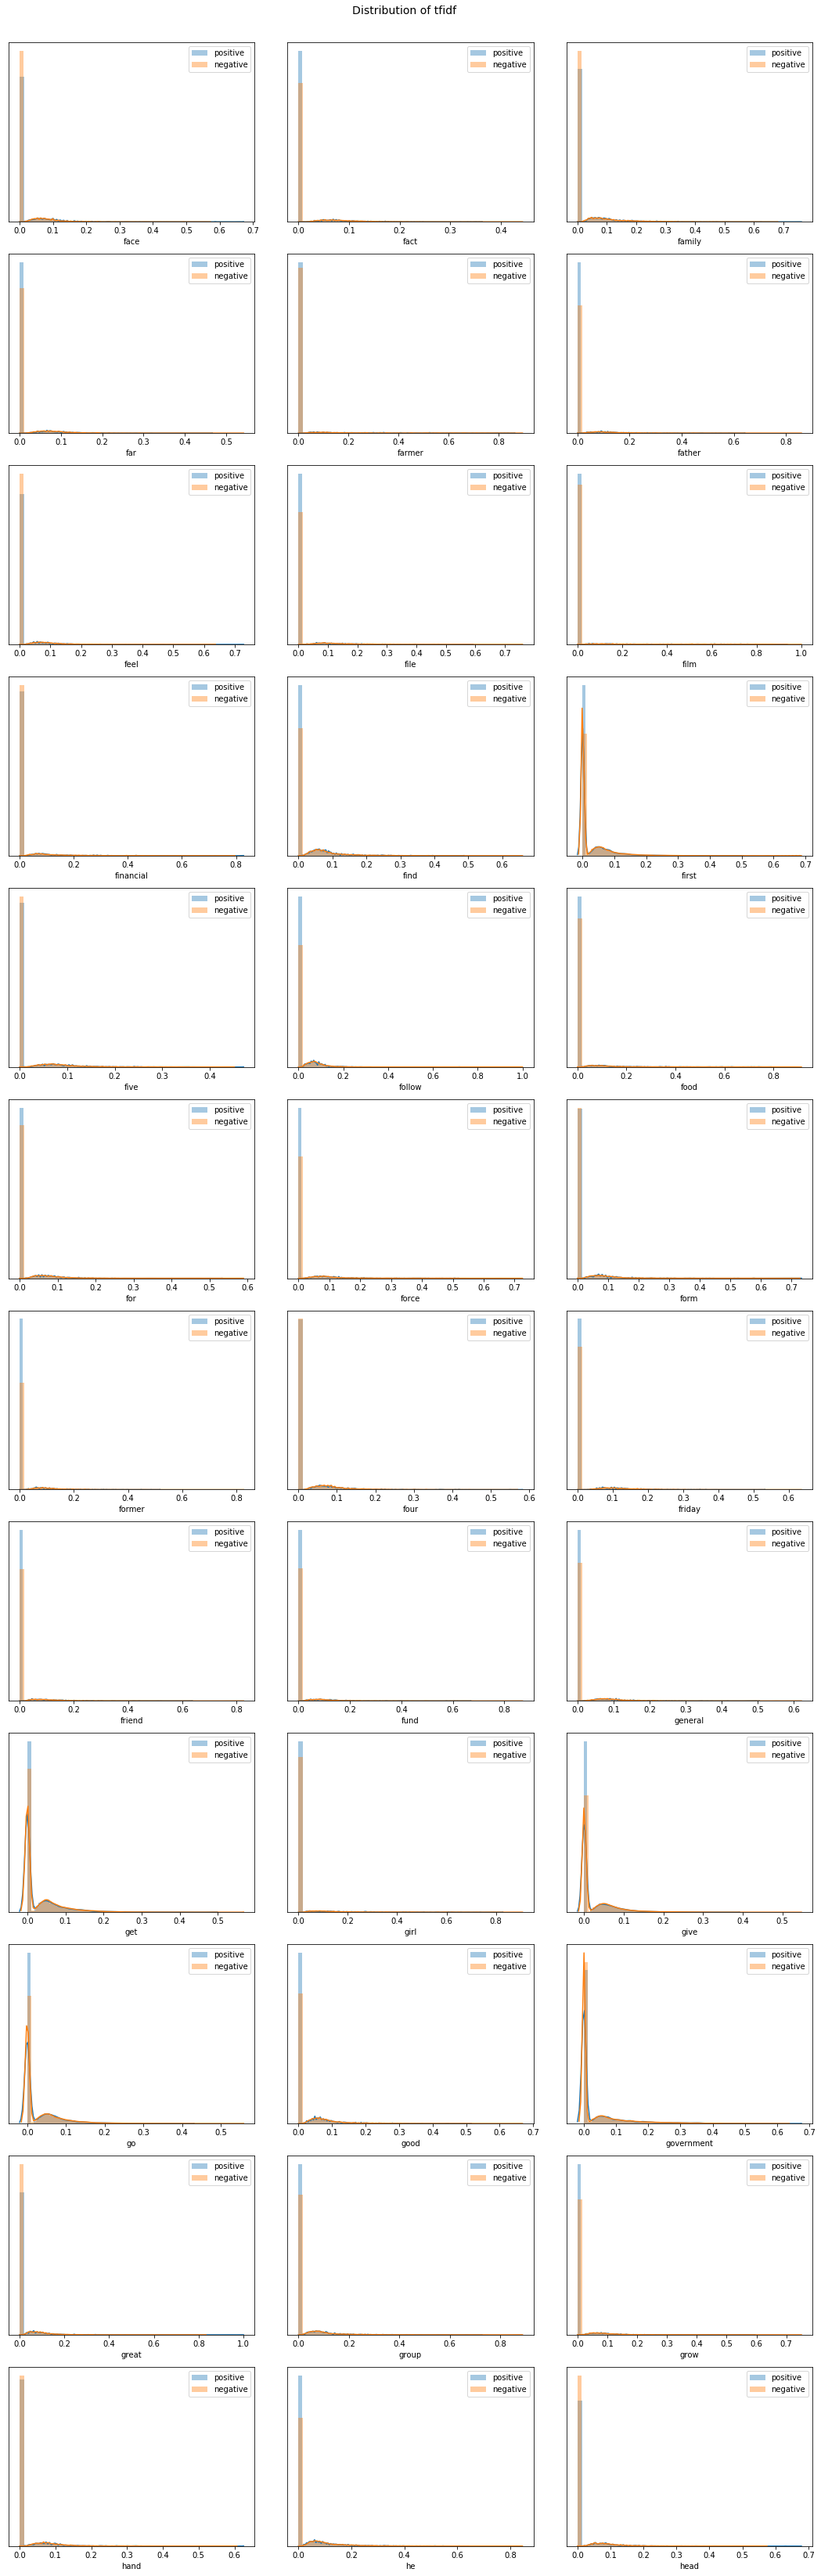

In [299]:
fig, axs = plt.subplots(nrows=12,ncols=3,figsize=(15,45))
axs = axs.flatten()
fig.suptitle('Distribution of tfidf',fontsize=14,y=1.01)
fig.tight_layout(h_pad=2)
col_list = list(tfidf_df.columns[100:136])
for ax,col in zip(axs,col_list):
    sns.distplot(tfidf_df[tfidf_df['is_positive']==1][col],ax=ax,label='positive')
    sns.distplot(tfidf_df[tfidf_df['is_positive']==0][col],ax=ax,label='negative')
    ax.set_xlabel(col)
    ax.set_yticks(ticks=[])
    ax.legend()
 

    The story continues... since most words are common to any peice of text(esentially the english language), most words have an overlapping distribution with slight difference merely because of the volume of data in the particular class. So we go ahead for modeling, Finally!

## Modeling

In [300]:
#wv is the word2vec embeddings object
#wv['happy']
#each row represents a document averaged by feature for all words
#doc - "this is good", first generate vectors for all 3 words then average each column for all the 3 words.
#Results in single row with with average of all words dimension wise
#that result is finally added to doc_vector i.e, each document will have one row
doc_vector = pd.DataFrame()
def create_mean_w2v(article):
    temp_df = pd.DataFrame()
    for word in set(article.split()):
        try:
            word_embed = wv[word]
            temp_df = temp_df.append(pd.Series(word_embed),ignore_index=True)
        except:
            pass
    return temp_df.mean()

doc_vector = doc_vector.append(all_data['lemmatized_content'].apply(create_mean_w2v))



In [301]:
wv_vec = doc_vector.copy(deep=True)
wv_vec[['text_length','mean_adj_length','unique_word_count','norm_adj_count','is_positive']] = all_data[['text_length','mean_adj_length','unique_word_count','norm_adj_count','is_positive']].copy(deep=True)
wv_vec['cd_jj_usage'] = pos_count_df['cd jj'].to_numpy()
wv_vec[['text_length','mean_adj_length','unique_word_count','adj_counmean_adjective_length','is_positive','cd_jj_usage']] = wv_vec[['text_length','mean_adj_length','unique_word_count','norm_adj_count','is_positive','cd_jj_usage']].progress_apply(minmax_scale)
wv_vec.fillna(value=0,inplace=True)



In [307]:
"""all_data_test = pd.DataFrame(x_test,columns=['content', 'actual_heading', 'clean_content', 'upper_words',
       'upper_count', 'word_count', 'mean(each_word_len)', 'unique_word_count',
       'punct_count', 'numeric_count', 'text_length', 'stop_words_percent',
       'content_sentiment', 'lemmatized_content', 'pos_content',
       'most_used_adjectives', 'adj_count', 'positive_score', 'negative_score',
       'mean_adj_length', 'heading_sentiment', 'lemmatized_heading',
       'pos_heading'])

all_data_test = norm_numerical_features(all_data_test)
all_data_test['content_sentiment'] = all_data_test['clean_content'].apply(get_document_sentiment)
all_data_test['clean_content'] = all_data_test['clean_content'].apply(rem_contractions)
all_data_test['lemmatized_content'][6620:21635] = all_data_test['clean_content'].apply(lemmatize_with_postag)
all_data_test['pos_content'] = all_data_test['lemmatized_content'].apply(pos_sentence)
all_data_test[['most_used_adjectives','adj_count']] = all_data_test.apply(most_used_adjectives,axis=1,result_type='expand')
all_data_test[['positive_score','negative_score']] = all_data_test.apply(pos_neg_score,axis=1,result_type='expand')
all_data_test[['mean_adj_length','all_adjs']] = all_data_test.apply(mean_adjective_length,axis=1,result_type='expand')
all_data_test['mean_adj_length'].fillna(0,inplace=True)
all_data_test['norm_adj_count'] = all_data_test['adj_count'] / all_data_test['word_count']

all_data_test['heading_sentiment'] = all_data_test['actual_heading'].apply(get_document_sentiment)
all_data_test['lemmatized_heading'] = all_data_test['actual_heading'].apply(lemmatize_with_postag)
all_data_test['pos_heading'] = all_data_test['lemmatized_heading'].apply(pos_sentence)


all_data_test.fillna(' ',inplace=True)
"""
count_vec_test = CountVectorizer(ngram_range=(2,3),max_features=300)
pos_count_df_test = count_vec_test.fit_transform(all_data_test['pos_content'])
pos_count_df_test = pd.DataFrame(data = pos_count_df_test.toarray() , columns = count_vec_test.get_feature_names())

doc_vector_test = pd.DataFrame()
def create_mean_w2v(article):
    temp_df = pd.DataFrame()
    for word in set(article.split()):
        try:
            word_embed = wv[word]
            temp_df = temp_df.append(pd.Series(word_embed),ignore_index=True)
        except:
            pass
    return temp_df.mean()

doc_vector_test = doc_vector_test.append(all_data_test['lemmatized_content'].apply(create_mean_w2v))
wv_vec_test = doc_vector_test.copy(deep=True)  

wv_vec_test[['text_length','mean_adj_length','unique_word_count','norm_adj_count']] = all_data_test[['text_length','mean_adj_length','unique_word_count','norm_adj_count']].copy(deep=True)

wv_vec_test['cd_jj_usage'] = pos_count_df_test['cd jj'].to_numpy()
wv_vec_test[['text_length','mean_adj_length','unique_word_count','adj_counmean_adjective_length','cd_jj_usage']] = wv_vec_test[['text_length','mean_adj_length','unique_word_count','norm_adj_count','cd_jj_usage']].progress_apply(minmax_scale)
wv_vec_test.fillna(value=0,inplace=True)

In [309]:
wv_vec_test.columns

Index([                              0,                               1,
                                     2,                               3,
                                     4,                               5,
                                     6,                               7,
                                     8,                               9,
       ...
                                   296,                             297,
                                   298,                             299,
                         'text_length',               'mean_adj_length',
                   'unique_word_count',                'norm_adj_count',
                         'cd_jj_usage', 'adj_counmean_adjective_length'],
      dtype='object', length=306)

    Most of the columns are mean vectors of documents, the others are the ones that we derived which distinguish positive and negative articles well

In [310]:
x_train = wv_vec.drop(labels=['is_positive'],axis=1).to_numpy()
x_test = wv_vec_test.to_numpy()

In [427]:
#baseline model Logistic Regression
log_reg = LogisticRegression().fit(x_train,y_train)
pred = log_reg.predict(x_test)
print(accuracy_score(pred,y_test))
print(classification_report(pred,y_test))


/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/sklearn/linear_model/logistic.py:432: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)


0.7903930131004366
              precision    recall  f1-score   support

           0       0.75      0.99      0.85      2083
           1       0.98      0.48      0.64      1352

    accuracy                           0.79      3435
   macro avg       0.86      0.74      0.75      3435
weighted avg       0.84      0.79      0.77      3435



    This is a decent classification report for any given model. We will consider this as our benchmark and will only pursue models that perform better than this
    
#### *lets look at some advanced models to see if they can do a better job given our data*

In [235]:
#the default svm model and parameters
svm_mod = svm.SVC(random_state=3)
print(svm_mod.get_params())

###Lets define some Hyperparameters to tune
C = [.0001, .001, .01]
degree = [1, 2, 3, 4, 5]
kernel = ['linear', 'rbf', 'poly']
probability = [True]
gamma = ['scale']


random_grid = {'C': C,
              'kernel': kernel,
              'degree': degree,
              'probability': probability,
              'gamma':gamma
             }


rand = RandomizedSearchCV(estimator=svm_mod, param_distributions=random_grid, n_iter=2, scoring='accuracy', 
                          cv=3, verbose=1, random_state=3)

tqdm(rand.fit(x_train,y_train))

print('best_parameters:svm {}'.format(rand.best_params_))
print('best_accuracy:svm {}'.format(rand.best_score_))    

best_svm = svm.SVC(probability= True, kernel= 'linear', degree= 5, C= 0.0001,random_state=3,gamma='scale')
best_svm.fit(x_train,y_train)
pred = best_svm.predict(x_test)
print(classification_report(y_true=y_test,y_pred=pred))
print(confusion_matrix(y_true=y_test,y_pred=pred))
print(accuracy_score(y_true=y_test,y_pred=pred))




{'C': 1.0, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'auto_deprecated', 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': 3, 'shrinking': True, 'tol': 0.001, 'verbose': False}
Fitting 3 folds for each of 2 candidates, totalling 6 fits


[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   6 out of   6 | elapsed: 56.0min finished


best_parameters:svm {'probability': True, 'kernel': 'poly', 'gamma': 'scale', 'degree': 5, 'C': 0.01}
best_accuracy:svm 0.8238833004495908
              precision    recall  f1-score   support

           0       0.81      1.00      0.89      2773
           1       0.00      0.00      0.00       662

    accuracy                           0.81      3435
   macro avg       0.40      0.50      0.45      3435
weighted avg       0.65      0.81      0.72      3435

[[2773    0]
 [ 662    0]]
0.8072780203784571


/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/sklearn/metrics/classification.py:1437: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples.
  'precision', 'predicted', average, warn_for)


    The model has 97% accuracy but is incapable of predicting positive articles. This sort of behavior is kind of expected given the imbalance in data. However, this was not expected from a model like svm, especially when a simpler model did well

In [ ]:
#####Decision Tree
#default model
dtc_mod = DecisionTreeClassifier(random_state=3)
print(dtc_mod.get_params())
#default parameters
'''{'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 
'min_impurity_decrease': 0.0, 'min_impurity_split': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 
'min_weight_fraction_leaf': 0.0, 'presort': False, 'random_state': 3, 'splitter': 'best'}'''

#tuning few hyperparameters
random_grid = {'criterion':['gini','entropy'],
               'max_depth':[10,12,15,20,80]}

rand = RandomizedSearchCV(estimator = dtc_mod, param_distributions=random_grid, n_iter=3, scoring='recall', cv=3, 
                          verbose=1, random_state=3)

rand.fit(x_train,y_train)

print('best parameters:dtc {}'.format(rand.best_params_))
print('best recall:dtc {}'.format(rand.best_score_))





In [429]:
best_dtc = DecisionTreeClassifier(criterion='entropy',max_depth=10,random_state=16)
best_dtc.fit(x_train,y_train)
pred = best_dtc.predict(x_test)

print(classification_report(y_true=y_test,y_pred=pred))
print(confusion_matrix(y_true=y_test,y_pred=pred))
print(accuracy_score(y_true=y_test,y_pred=pred))



              precision    recall  f1-score   support

           0       0.95      0.72      0.82      2773
           1       0.42      0.84      0.56       662

    accuracy                           0.75      3435
   macro avg       0.68      0.78      0.69      3435
weighted avg       0.85      0.75      0.77      3435

[[2006  767]
 [ 108  554]]
0.745269286754003


    Though the accuracy is lesser than svm, looks like dtc is able to differentiate pos and neg better than svm. Our motto is to classify as many positive articles as possible under it's right class. For that reason our concentration is on recall more than accuracy.


In [430]:

#######KNeighborsClassifier
knc_mod = KNeighborsClassifier()
print('default parameters: {}'.format(knc_mod.get_params()))


random_grid = {'weights':['uniform','distance'],
               'n_neighbors':[3,5,7,10,12], 
               'p':[1,2]}

rand = RandomizedSearchCV(estimator=knc_mod, param_distributions=random_grid, n_iter=3, scoring='recall', cv=3,
                          random_state=3)
rand.fit(x_train,y_train)
print('best parameters:knc {}'.format(rand.best_params_))
print('best reacall:knc {}'.format(rand.best_score_))


default parameters: {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
best parameters:knc {'weights': 'distance', 'p': 1, 'n_neighbors': 3}
best reacall:knc 0.8598338407195498


In [431]:
best_knc = KNeighborsClassifier(weights='distance',p=1,n_neighbors=3)
best_knc.fit(x_train,y_train)
pred = best_knc.predict(x_test)

print(classification_report(y_true=y_test,y_pred=pred))
print(confusion_matrix(y_true=y_test,y_pred=pred))
print(accuracy_score(y_true=y_test,y_pred=pred))

              precision    recall  f1-score   support

           0       0.98      0.90      0.94      2773
           1       0.68      0.94      0.79       662

    accuracy                           0.90      3435
   macro avg       0.83      0.92      0.86      3435
weighted avg       0.93      0.90      0.91      3435

[[2482  291]
 [  39  623]]
0.9039301310043668


In [266]:
from sklearn.naive_bayes import GaussianNB

In [435]:
gnb = GaussianNB(var_smoothing=0.00000001)
gnb.partial_fit(x_train,y_train,np.unique(y_train))
pred = gnb.predict(x_test)
print(accuracy_score(y_test,pred))
print(confusion_matrix(y_test,pred))
print(classification_report(y_true=y_test,y_pred=pred))

0.7953420669577875
[[2200  573]
 [ 130  532]]
              precision    recall  f1-score   support

           0       0.94      0.79      0.86      2773
           1       0.48      0.80      0.60       662

    accuracy                           0.80      3435
   macro avg       0.71      0.80      0.73      3435
weighted avg       0.86      0.80      0.81      3435



    So far, our best performer is KNeighborClassifier at a recall of 94. Since it is our best model, we can save it and directly run it on unseen data whenever necessary.
    
    The other model that we are interested in is GaussiaNaiveBayes at a recall of 80. This model is interesting because it has the capability of mimicking online learning by partially fitting the current training data and incrementally learns whenever fit on the new training data.

In [437]:
#GaussianNB saved model
filename = '/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/gnb.gz'
joblib.dump(gnb,open(filename,'wb'),compress=3)

gnb_loaded = joblib.load(open(filename,'rb'))
pred = gnb_loaded.predict(x_test)
print(classification_report(y_test,pred))

In [239]:
#KNeighborsClassifier saved model
filename = '/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/best_knc.sav'
pickle.dump(best_knc,open(filename,'wb'))

trained_knc = pickle.load(open(filename,'rb'))
pred = trained_knc.predict(x_test)
confusion_matrix(y_test,pred)

# Next steps

    Now that we have successfully created a model that is stable and produces good results on unseen data it's time to explore more ways to tackle our problem. One such way is to use Unsupervised Learning - combining all the the available data and looking at it without attaching the label. We encourage you to try your own ideas and explore the unexplored waters
